In [1]:
# Install packages

%pip install -q "setuptools<81" "polars>=1.20" "pyarrow>=15" "pandas>=2.0" "matplotlib>=3.7" "seaborn>=0.13" "ydata-profiling>=4.12"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.4 MB/s eta 0:00:00


In [2]:
# 1. Import libraries


import os
import re
import shutil
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path

os.environ["POLARS_UNKNOWN_EXTENSION_TYPE_BEHAVIOR"] = "load_as_storage"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.dataset as pds
import pyarrow.parquet as pq
import seaborn as sns
import platform
import matplotlib
from IPython.display import FileLink, Image, Markdown, display
import importlib

warnings.filterwarnings("ignore", message="Extension type.*not registered")
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(40)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_SEED = 2026
EXPECTED_MONTHS = {f"2025-{m:02d}" for m in range(1, 13)}
EXPECTED_AIRPORTS = {"EDDF", "EDDM", "EGLL", "EHAM", "LEBL",
                     "LEMD", "LFPG", "LIRF", "LTFM", "LSZH"}
REQUIRED_COLUMNS = {
    "MVT_ID_mvt", "FLIGHT_ID_mvt", "PHASE_mvt", "ADEP_mvt", "ADES_mvt",
    "BLOCK_TIME_UTC_mvt", "MVT_TIME_UTC_mvt", "TAXITIME_SEC_mvt"
}
TARGET = "TAXITIME_SEC_mvt"
OUTPUT_DIR = Path("reports/sep20_eda")
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
PROFILE_DIR = OUTPUT_DIR / "profiling"
for directory in (TABLE_DIR, FIGURE_DIR, PROFILE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Polars:", pl.__version__)
print("Outputs:", OUTPUT_DIR.resolve())

Polars: 1.35.2
Outputs: /content/reports/sep20_eda


In [3]:
#  DATA INGESTION & UNDERSTANDING — Locate and verify files


from pathlib import Path

DATA_DIR = Path("/content")
training_files = sorted(DATA_DIR.glob("training_*.parquet"))

if len(training_files) != 12:
    raise FileNotFoundError(
        f"Expected 12 training Parquet files in {DATA_DIR}, "
        f"but found {len(training_files)}."
    )

print("All 12 training files found:")
for path in training_files:
    print("✓", path.name)

All 12 training files found:
✓ training_2025-01-01_2025-02-01.parquet
✓ training_2025-02-01_2025-03-01.parquet
✓ training_2025-03-01_2025-04-01.parquet
✓ training_2025-04-01_2025-05-01.parquet
✓ training_2025-05-01_2025-06-01.parquet
✓ training_2025-06-01_2025-07-01.parquet
✓ training_2025-07-01_2025-08-01.parquet
✓ training_2025-08-01_2025-09-01.parquet
✓ training_2025-09-01_2025-10-01.parquet
✓ training_2025-10-01_2025-11-01.parquet
✓ training_2025-11-01_2025-12-01.parquet
✓ training_2025-12-01_2026-01-01.parquet


In [4]:
#  File inventory
# Read exact row counts, dimensions, monthly windows, and file sizes from Parquet metadata.

inventory_rows = []
for path in training_files:
    metadata = pq.ParquetFile(path).metadata
    match = re.search(r"training_(\d{4}-\d{2}-\d{2})_(\d{4}-\d{2}-\d{2})", path.name)
    start_date, end_date = (match.group(1), match.group(2)) if match else (None, None)
    inventory_rows.append({
        "file": path.name,
        "expected_start": start_date,
        "expected_end_exclusive": end_date,
        "expected_month": start_date[:7] if start_date else None,
        "size_mb": round(path.stat().st_size / 1024**2, 2),
        "rows": metadata.num_rows,
        "columns": metadata.num_columns,
        "row_groups": metadata.num_row_groups,
    })

file_inventory = pd.DataFrame(inventory_rows).sort_values("expected_month")
display(file_inventory)
print("Metadata row total:", f"{file_inventory['rows'].sum():,}")
file_inventory.to_csv(TABLE_DIR / "file_inventory.csv", index=False)

,file,expected_start,expected_end_exclusive,expected_month,size_mb,rows,columns,row_groups
0,training_2025-01-01_2025-02-01.parquet,2025-01-01,2025-02-01,2025-01,20.24,307257,30,1
1,training_2025-02-01_2025-03-01.parquet,2025-02-01,2025-03-01,2025-02,18.91,287411,30,1
2,training_2025-03-01_2025-04-01.parquet,2025-03-01,2025-04-01,2025-03,21.56,328622,30,1
3,training_2025-04-01_2025-05-01.parquet,2025-04-01,2025-05-01,2025-04,22.74,350288,30,1
4,training_2025-05-01_2025-06-01.parquet,2025-05-01,2025-06-01,2025-05,24.02,370105,30,1
5,training_2025-06-01_2025-07-01.parquet,2025-06-01,2025-07-01,2025-06,23.83,365986,30,1
6,training_2025-07-01_2025-08-01.parquet,2025-07-01,2025-08-01,2025-07,24.81,381161,30,1
7,training_2025-08-01_2025-09-01.parquet,2025-08-01,2025-09-01,2025-08,24.77,382047,30,1
8,training_2025-09-01_2025-10-01.parquet,2025-09-01,2025-10-01,2025-09,23.94,367679,30,1
9,training_2025-10-01_2025-11-01.parquet,2025-10-01,2025-11-01,2025-10,24.22,371163,30,1


Metadata row total: 4,167,797


In [5]:
# Schema inspection
# Compare every monthly schema with the first month and record any missing columns or type drift.

schemas = {}
for path in training_files:
    schema = pq.ParquetFile(path).schema_arrow
    schemas[path.name] = {field.name: str(field.type) for field in schema}

all_columns = sorted(set().union(*(set(s) for s in schemas.values())))
reference_file = training_files[0].name
reference_schema = schemas[reference_file]
schema_rows = []
for file_name, schema in schemas.items():
    for column in all_columns:
        dtype = schema.get(column)
        schema_rows.append({
            "file": file_name,
            "column": column,
            "present": column in schema,
            "dtype": dtype,
            "reference_dtype": reference_schema.get(column),
            "type_matches_reference": dtype == reference_schema.get(column),
        })

schema_comparison = pd.DataFrame(schema_rows)
schema_issues = schema_comparison.query("not present or not type_matches_reference")
print("Schema differences found:", len(schema_issues))
display(schema_issues.head(30) if len(schema_issues) else pd.DataFrame({"result": ["No schema drift detected"]}))
schema_comparison.to_csv(TABLE_DIR / "schema_comparison.csv", index=False)

Schema differences found: 0


,result
0,No schema drift detected


In [6]:
#  Data preview
# Inspect five records from the first monthly file without loading the full dataset.

first_batch = next(pq.ParquetFile(training_files[0]).iter_batches(batch_size=5))
data_preview = pa.Table.from_batches([first_batch]).to_pandas()
display(data_preview)
print(f"Preview source: {training_files[0].name}")

,MVT_ID_mvt,FLIGHT_ID_mvt,FLIGHT_mvt,FLIGHT_RULE_mvt,ADEP_mvt,ADES_mvt,PHASE_mvt,MVT_TIME_UTC_mvt,BLOCK_TIME_UTC_mvt,SCHED_TIME_UTC_mvt,AIRCRAFT_TYPE_mvt,RUNWAY_mvt,STAND_mvt,TAXITIME_SEC_mvt,LOBT_flt,CALLSIGN_flt,ADEP_flt,ADES_flt,ADES_FILED_flt,MARKET_SEGMENT_flt,IOBT_flt,FLIGHT_RULE_flt,FLIGHT_TYPE_flt,AIRCRAFT_TYPE_flt,WK_TBL_CAT_flt,AIRCRAFT_OPERATOR_flt,EOBT_1_flt,ARVT_1_flt,AOBT_3_flt,ARVT_3_flt
0,182234017.0,280602939.0,LH982,I,EDDF,EIDW,DEP,2025-01-07 21:10:06+00:00,2025-01-07 21:00:11+00:00,2025-01-07 21:00:00+00:00,A320,25C,B41,595,2025-01-07 21:00:00+00:00,DLH8UL,EDDF,EIDW,EIDW,Mainline,2025-01-07 21:00:00+00:00,I,S,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-01-07 21:00:00+00:00,2025-01-07 23:11:12+00:00,2025-01-07 20:57:00+00:00,2025-01-07 22:58:31+00:00
1,182249437.0,280601336.0,LO383,I,EPWA,EDDF,ARR,2025-01-07 21:10:32+00:00,2025-01-07 21:18:57+00:00,2025-01-07 21:10:00+00:00,E75S,25C,V115,505,2025-01-07 19:22:00+00:00,LOT3MA,EPWA,EDDF,EDDF,Regional,2025-01-07 19:22:00+00:00,I,S,E170,M,1e218b1a730a8fe295a6547b48d215268be4ae3030d571...,2025-01-07 19:22:00+00:00,2025-01-07 21:15:43+00:00,2025-01-07 19:16:00+00:00,2025-01-07 21:10:28+00:00
2,182234011.0,280602803.0,LH796,I,EDDF,VHHH,DEP,2025-01-07 21:11:23+00:00,2025-01-07 20:53:18+00:00,2025-01-07 20:50:00+00:00,A346,18,A20,1085,2025-01-07 20:50:00+00:00,DLH796,EDDF,VHHH,VHHH,Mainline,2025-01-07 20:50:00+00:00,I,S,A346,H,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-01-07 20:50:00+00:00,2025-01-08 08:21:09+00:00,2025-01-07 20:53:00+00:00,2025-01-08 08:22:32+00:00
3,182234021.0,280602920.0,LH958,I,EDDF,EGBB,DEP,2025-01-07 21:12:29+00:00,2025-01-07 21:01:01+00:00,2025-01-07 21:00:00+00:00,A320,25C,B48,688,2025-01-07 21:00:00+00:00,DLH2HU,EDDF,EGBB,EGBB,Mainline,2025-01-07 21:00:00+00:00,I,S,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-01-07 21:00:00+00:00,2025-01-07 22:33:40+00:00,2025-01-07 21:01:00+00:00,2025-01-07 22:36:05+00:00
4,182249434.0,280602048.0,LH121,I,EDDM,EDDF,ARR,2025-01-07 21:13:01+00:00,2025-01-07 21:18:14+00:00,2025-01-07 21:05:00+00:00,A320,25C,A17,313,2025-01-07 20:00:00+00:00,DLH9EF,EDDM,EDDF,EDDF,Mainline,2025-01-07 20:00:00+00:00,I,S,A320,M,11dca3faf5500fdddbb17189b5d18bcdc763244fcc850c...,2025-01-07 20:00:00+00:00,2025-01-07 21:01:21+00:00,2025-01-07 20:16:00+00:00,2025-01-07 21:13:45+00:00


Preview source: training_2025-01-01_2025-02-01.parquet


In [7]:
#  Data dictionary
# Record official meanings, source domains, expected types, and EDA interpretation.

data_dictionary = pd.DataFrame([
    ["MVT_ID_mvt", "Movement", "Unique movement-record identifier", "Float in source; integer-valued ID", "Expected globally unique"],
    ["FLIGHT_ID_mvt", "Movement", "Unique NM flight identifier when matched", "Float in source", "Null can represent an unmatched left-join result"],
    ["FLIGHT_mvt", "Movement", "Commercial flight number shown to passengers", "String/category", "Not semantically equivalent to an operational callsign"],
    ["PHASE_mvt", "Movement", "DEP=departure; ARR=arrival", "String/category", "Taxi-out modelling uses DEP only"],
    ["ADEP_mvt", "Movement", "Aerodrome of departure ICAO code", "String/category", "Reporting airport for DEP"],
    ["ADES_mvt", "Movement", "Aerodrome of destination ICAO code", "String/category", "Reporting airport for ARR"],
    ["BLOCK_TIME_UTC_mvt", "Movement", "Off-block for DEP; in-block for ARR", "UTC datetime", "Official phase-dependent definition"],
    ["MVT_TIME_UTC_mvt", "Movement", "Take-off for DEP; landing for ARR", "UTC datetime", "Official phase-dependent definition"],
    ["SCHED_TIME_UTC_mvt", "Movement", "Scheduled departure for DEP; scheduled arrival for ARR", "UTC datetime", "Official phase-dependent definition"],
    ["TAXITIME_SEC_mvt", "Movement", "Taxi-out for DEP; taxi-in for ARR", "Integer seconds", "Prediction target only for DEP"],
    ["CALLSIGN_flt", "Flight", "Operational NM flight callsign", "String/category", "Must not be compared as if identical to FLIGHT_mvt"],
    ["ADEP_flt / ADES_flt", "Flight", "NM departure/destination aerodromes", "String/category", "Differences from _mvt fields are source inconsistencies, not proof of a broken join"],
    ["FLIGHT_TYPE_flt", "Flight", "S, N, G, M or X flight type", "String/category", "M is military; provider documentation says military movements were filtered upstream"],
    ["MARKET_SEGMENT_flt", "Flight", "NM market-segment classification", "String/category", "Includes a Military label in the documented domain"],
    ["*_flt", "Flight", "Attributes from the organiser-supplied left-joined NM record", "Mixed", "Audit completeness and source consistency"],
], columns=["column", "source_domain", "official_meaning", "expected_type", "eda_interpretation"])
display(data_dictionary)
data_dictionary.to_csv(TABLE_DIR / "data_dictionary.csv", index=False)

,column,source_domain,official_meaning,expected_type,eda_interpretation
0,MVT_ID_mvt,Movement,Unique movement-record identifier,Float in source; integer-valued ID,Expected globally unique
1,FLIGHT_ID_mvt,Movement,Unique NM flight identifier when matched,Float in source,Null can represent an unmatched left-join result
2,FLIGHT_mvt,Movement,Commercial flight number shown to passengers,String/category,Not semantically equivalent to an operational ...
3,PHASE_mvt,Movement,DEP=departure; ARR=arrival,String/category,Taxi-out modelling uses DEP only
4,ADEP_mvt,Movement,Aerodrome of departure ICAO code,String/category,Reporting airport for DEP
5,ADES_mvt,Movement,Aerodrome of destination ICAO code,String/category,Reporting airport for ARR
6,BLOCK_TIME_UTC_mvt,Movement,Off-block for DEP; in-block for ARR,UTC datetime,Official phase-dependent definition
7,MVT_TIME_UTC_mvt,Movement,Take-off for DEP; landing for ARR,UTC datetime,Official phase-dependent definition
8,SCHED_TIME_UTC_mvt,Movement,Scheduled departure for DEP; scheduled arrival...,UTC datetime,Official phase-dependent definition
9,TAXITIME_SEC_mvt,Movement,Taxi-out for DEP; taxi-in for ARR,Integer seconds,Prediction target only for DEP


In [8]:
#  Build unified dataset
# Create one lineage-aware Polars view, standardise phase/airport fields, and materialise the 4.1M-row training dataset once for reuse.

def storage_only_arrow_schema(path: Path) -> pa.Schema:
    '''Keep physical Arrow types but remove R-specific field extension metadata.'''
    source_schema = pq.read_schema(path)
    return pa.schema([
        pa.field(field.name, field.type, nullable=field.nullable, metadata=None)
        for field in source_schema
    ], metadata=None)


print("Using a PyArrow storage-schema view to bypass arrow.r.vctrs metadata safely.")
clean_arrow_schema = storage_only_arrow_schema(training_files[0])
monthly_lazy_frames = []
for path in training_files:
    arrow_dataset = pds.dataset(str(path), format="parquet", schema=clean_arrow_schema)
    monthly_lazy_frames.append(
        pl.scan_pyarrow_dataset(arrow_dataset)
          .with_columns(pl.lit(str(path)).alias("source_file"))
    )
raw = pl.concat(monthly_lazy_frames, how="vertical_relaxed")
raw_schema = raw.collect_schema()
parquet_scan_method = "PyArrow storage-schema view"

data = raw.with_columns([
    pl.col("source_file").str.extract(r"training_(\d{4}-\d{2})", 1).alias("source_month"),
    pl.when(pl.col("PHASE_mvt").str.strip_chars().str.to_uppercase() == "DEP")
      .then(pl.col("ADEP_mvt").str.strip_chars().str.to_uppercase())
      .when(pl.col("PHASE_mvt").str.strip_chars().str.to_uppercase() == "ARR")
      .then(pl.col("ADES_mvt").str.strip_chars().str.to_uppercase())
      .otherwise(None)
      .alias("movement_airport"),
    pl.col("PHASE_mvt").str.strip_chars().str.to_uppercase().alias("phase_standardised"),
])

# Every downstream cell calls `data.filter(...).group_by(...).collect()`. Without this line,
# each of those calls independently re-scans and re-decodes all 12 Parquet files plus
# re-derives source_month/movement_airport/phase_standardised from scratch. Collecting once
# here and wrapping the result back in .lazy() keeps every downstream cell's syntax identical
# while making every later .collect() run against the already-materialised in-memory table.
data = data.collect().lazy()

dataset_shape = data.select([
    # Referencing a physical column avoids an empty-projection edge case in scan_pyarrow_dataset.
    pl.col("MVT_ID_mvt").len().alias("rows"),
    pl.lit(len(reference_schema)).alias("raw_file_columns"),
    pl.lit(len(raw_schema)).alias("analysis_columns_including_lineage"),
]).collect()
display(dataset_shape)
print("Scanner used:", parquet_scan_method)

Using a PyArrow storage-schema view to bypass arrow.r.vctrs metadata safely.


rows,raw_file_columns,analysis_columns_including_lineage
u32,i32,i32
4167797,30,31


Scanner used: PyArrow storage-schema view


In [9]:
# DATA QUALITY —  Coverage
# Verify months, airports, phases, airport × month × phase coverage, and monthly record totals.

phase_summary = (
    data.group_by("PHASE_mvt", "phase_standardised")
        .agg(pl.len().alias("rows"))
        .with_columns((pl.col("rows") / pl.col("rows").sum() * 100).alias("percent"))
        .sort("rows", descending=True)
        .collect()
)
display(phase_summary)

coverage = (
    data.group_by("source_month", "movement_airport", "phase_standardised")
        .agg(pl.len().alias("rows"))
        .sort("source_month", "movement_airport", "phase_standardised")
        .collect()
)
target_coverage = coverage.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
observed_months = set(data.select("source_month").unique().collect().to_series().to_list())
observed_target_airports = set(target_coverage.select("movement_airport").unique().to_series().to_list())

print("Missing months:", sorted(EXPECTED_MONTHS - observed_months))
print("Missing target airports:", sorted(EXPECTED_AIRPORTS - observed_target_airports))
display(target_coverage.head(30))
phase_summary.write_csv(TABLE_DIR / "phase_summary.csv")
coverage.write_csv(TABLE_DIR / "airport_month_phase_coverage.csv")

monthly_inventory = (
    data.group_by("source_month")
        .agg([
            pl.len().alias("rows"),
            pl.col("MVT_ID_mvt").n_unique().alias("unique_mvt_ids"),
            (pl.len() - pl.col("MVT_ID_mvt").n_unique()).alias("duplicate_id_excess_rows"),
            (pl.col("phase_standardised") == "DEP").sum().alias("departures"),
            (pl.col("phase_standardised") == "ARR").sum().alias("arrivals"),
            pl.col("movement_airport").filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS))).n_unique().alias("target_airports"),
            pl.col("BLOCK_TIME_UTC_mvt").min().alias("min_block_time"),
            pl.col("BLOCK_TIME_UTC_mvt").max().alias("max_block_time"),
            pl.col("BLOCK_TIME_UTC_mvt").null_count().alias("missing_block_time"),
            pl.col("MVT_TIME_UTC_mvt").null_count().alias("missing_movement_time"),
            pl.col(TARGET).null_count().alias("missing_target"),
            pl.col("FLIGHT_ID_mvt").null_count().alias("missing_flight_id"),
        ])
        .sort("source_month")
        .collect()
)
display(monthly_inventory)
monthly_inventory.write_csv(TABLE_DIR / "monthly_inventory.csv")

PHASE_mvt,phase_standardised,rows,percent
str,str,u32,f64
"""DEP""","""DEP""",2085047,50.027557
"""ARR""","""ARR""",2082750,49.972443


Missing months: []
Missing target airports: []


source_month,movement_airport,phase_standardised,rows
str,str,str,u32
"""2025-01""","""EDDF""","""ARR""",15432
"""2025-01""","""EDDF""","""DEP""",15496
"""2025-01""","""EDDM""","""ARR""",11215
"""2025-01""","""EDDM""","""DEP""",11266
"""2025-01""","""EGLL""","""ARR""",19427
"""2025-01""","""EGLL""","""DEP""",19420
"""2025-01""","""EHAM""","""ARR""",18469
"""2025-01""","""EHAM""","""DEP""",18460
"""2025-01""","""LEBL""","""ARR""",12165


source_month,rows,unique_mvt_ids,duplicate_id_excess_rows,departures,arrivals,target_airports,min_block_time,max_block_time,missing_block_time,missing_movement_time,missing_target,missing_flight_id
str,u32,u32,u32,u32,u32,u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,u32,u32,u32
"""2025-01""",307257,307257,0,153706,153551,10,2024-12-31 23:38:00 UTC,2025-01-31 23:56:02 UTC,0,0,0,2059
"""2025-02""",287411,287411,0,143731,143680,10,2025-02-01 00:13:57 UTC,2025-02-28 23:55:05 UTC,0,0,0,1692
"""2025-03""",328622,328622,0,164450,164172,10,2025-02-28 23:47:03 UTC,2025-03-31 23:08:56 UTC,0,0,0,1769
"""2025-04""",350288,350288,0,175288,175000,10,2025-03-31 23:30:00 UTC,2025-04-30 23:42:00 UTC,0,0,0,1758
"""2025-05""",370105,370105,0,185202,184903,10,2025-04-30 22:15:05 UTC,2025-05-31 23:51:57 UTC,0,0,0,2322
"""2025-06""",365986,365986,0,183142,182844,10,2025-05-31 23:49:58 UTC,2025-06-30 23:59:02 UTC,0,0,0,3336
"""2025-07""",381161,381161,0,190713,190448,10,2025-06-30 23:46:59 UTC,2025-08-01 03:56:05 UTC,0,0,0,4783
"""2025-08""",382047,382047,0,191181,190866,10,2025-07-31 23:30:04 UTC,2025-08-31 23:58:57 UTC,0,0,0,3130
"""2025-09""",367679,367679,0,183951,183728,10,2025-08-31 23:37:58 UTC,2025-09-30 23:51:58 UTC,0,0,0,3141


,column,dtype,null_count,null_percent,blank_count,blank_percent,confirmed_missing_count,confirmed_missing_percent,suspicious_token_count_not_auto_missing
21,FLIGHT_RULE_flt,String,38060,0.913192,0,0.0,38060,0.913192,0
24,WK_TBL_CAT_flt,String,38060,0.913192,0,0.0,38060,0.913192,0
16,ADEP_flt,String,37919,0.909809,0,0.0,37919,0.909809,0
18,ADES_FILED_flt,String,37919,0.909809,0,0.0,37919,0.909809,0
17,ADES_flt,String,37919,0.909809,0,0.0,37919,0.909809,0
25,AIRCRAFT_OPERATOR_flt,String,37919,0.909809,0,0.0,37919,0.909809,0
23,AIRCRAFT_TYPE_flt,String,37919,0.909809,0,0.0,37919,0.909809,0
28,AOBT_3_flt,"Datetime(time_unit='us', time_zone='UTC')",37919,0.909809,0,0.0,37919,0.909809,0
27,ARVT_1_flt,"Datetime(time_unit='us', time_zone='UTC')",37919,0.909809,0,0.0,37919,0.909809,0
29,ARVT_3_flt,"Datetime(time_unit='us', time_zone='UTC')",37919,0.909809,0,0.0,37919,0.909809,0


,column,documented_allowed_values,observed_non_null_values,invalid_values,invalid_count
0,PHASE_mvt,"ARR, DEP","ARR, DEP",,0
1,FLIGHT_RULE_mvt,"I, NA, V","I, V",,0
2,FLIGHT_RULE_flt,"I, V, Y, Z","I, V, Y, Z",,0
3,FLIGHT_TYPE_flt,"G, M, N, S, X","G, M, N, S, X",,0


source_month,movement_airport,phase_standardised,rows,missing_block,missing_movement,missing_target,both_present,block_only,movement_only,both_missing,missing_block_pct,missing_movement_pct,missing_target_pct
str,str,str,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64
"""2025-01""","""EDDF""","""ARR""",15432,0,0,0,15432,0,0,0,0.0,0.0,0.0
"""2025-01""","""EDDF""","""DEP""",15496,0,0,0,15496,0,0,0,0.0,0.0,0.0
"""2025-01""","""EDDM""","""ARR""",11215,0,0,0,11215,0,0,0,0.0,0.0,0.0
"""2025-01""","""EDDM""","""DEP""",11266,0,0,0,11266,0,0,0,0.0,0.0,0.0
"""2025-01""","""EGLL""","""ARR""",19427,0,0,0,19427,0,0,0,0.0,0.0,0.0
"""2025-01""","""EGLL""","""DEP""",19420,0,0,0,19420,0,0,0,0.0,0.0,0.0
"""2025-01""","""EHAM""","""ARR""",18469,0,0,0,18469,0,0,0,0.0,0.0,0.0
"""2025-01""","""EHAM""","""DEP""",18460,0,0,0,18460,0,0,0,0.0,0.0,0.0
"""2025-01""","""LEBL""","""ARR""",12165,0,0,0,12165,0,0,0,0.0,0.0,0.0


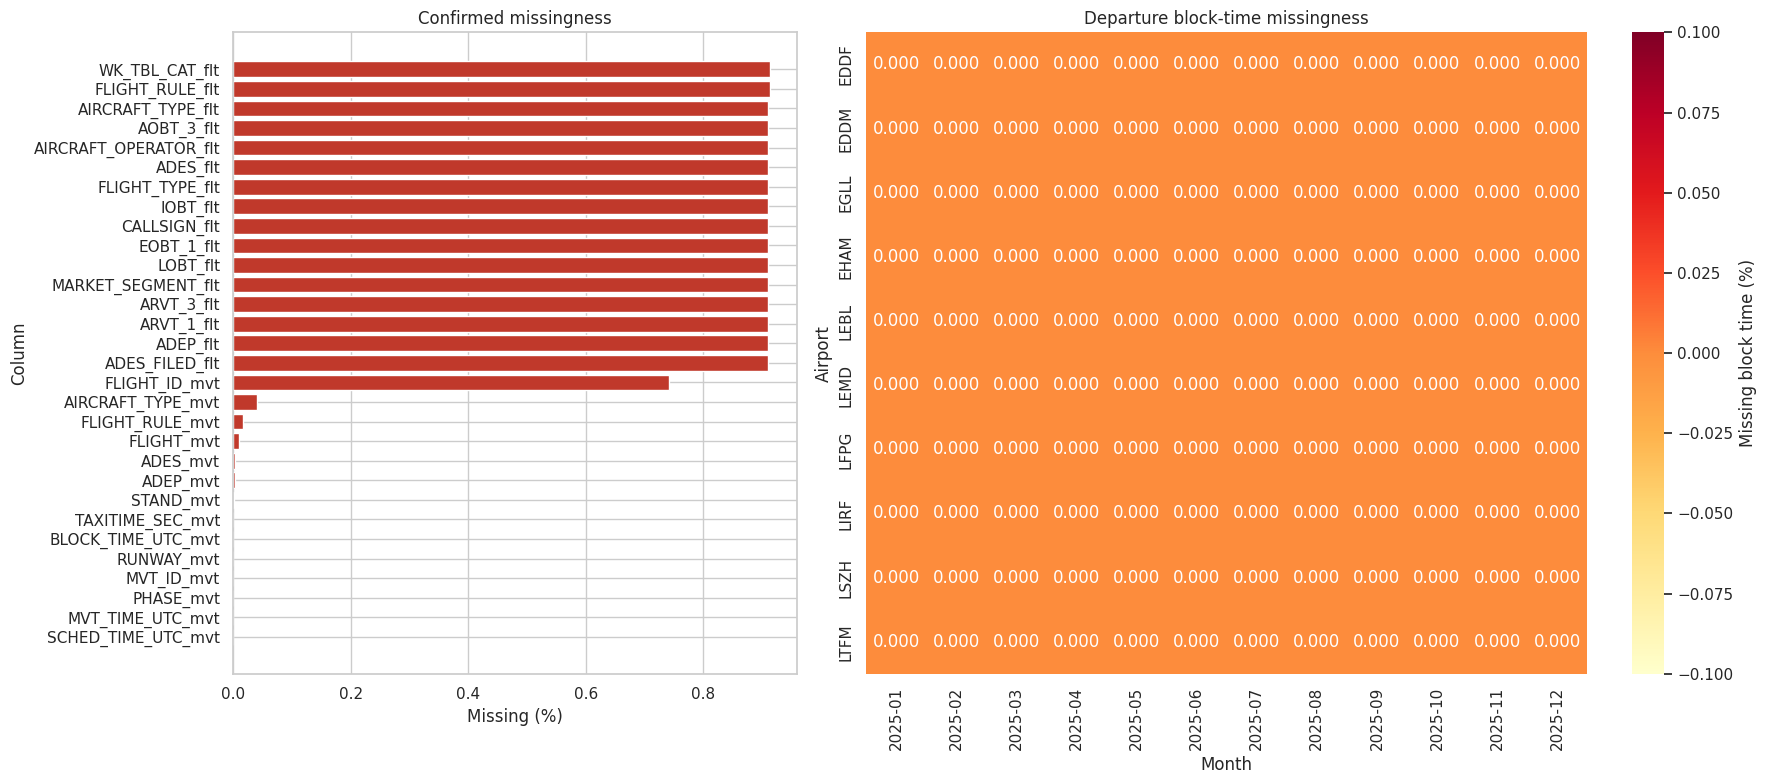

In [10]:
#  Missingness
# Measure nulls, blanks, suspicious tokens, categorical-domain violations, grouped missingness, and timestamp-null co-occurrence.

# Reuses the row count already measured once in section 7 (dataset_shape) instead of a fresh scan.
total_rows = int(dataset_shape.select("rows").item())
string_columns = [name for name, dtype in raw_schema.items() if dtype == pl.String]

# "NA" is not included: it is an officially documented FLIGHT_RULE_mvt category.
SUSPICIOUS_TEXT_TOKENS = {"N/A", "NULL", "NONE"}
DOCUMENTED_CATEGORIES = {
    "PHASE_mvt": {"DEP", "ARR"},
    "FLIGHT_RULE_mvt": {"I", "V", "NA"},
    "FLIGHT_RULE_flt": {"I", "V", "Y", "Z"},
    "FLIGHT_TYPE_flt": {"S", "N", "G", "M", "X"},
}

null_counts = data.select(
    [pl.col(c).null_count().alias(c) for c in raw_schema.names()]
).collect().row(0, named=True)

blank_counts = data.select([
    (
        pl.col(c).is_not_null() &
        (pl.col(c).str.strip_chars() == "")
    ).sum().alias(c)
    for c in string_columns
]).collect().row(0, named=True)

suspicious_token_counts = data.select([
    pl.col(c).str.strip_chars().str.to_uppercase()
    .is_in(sorted(SUSPICIOUS_TEXT_TOKENS)).fill_null(False)
    .sum().alias(c)
    for c in string_columns
]).collect().row(0, named=True)

missingness_rows = []
for c in raw_schema.names():
    null_count = int(null_counts[c])
    blank_count = int(blank_counts.get(c, 0))
    suspicious_count = int(suspicious_token_counts.get(c, 0))
    missingness_rows.append({
        "column": c,
        "dtype": str(raw_schema[c]),
        "null_count": null_count,
        "null_percent": 100 * null_count / total_rows,
        "blank_count": blank_count,
        "blank_percent": 100 * blank_count / total_rows,
        "confirmed_missing_count": null_count + blank_count,
        "confirmed_missing_percent": 100 * (null_count + blank_count) / total_rows,
        "suspicious_token_count_not_auto_missing": suspicious_count,
    })

overall_missingness = pd.DataFrame(missingness_rows).sort_values(
    ["confirmed_missing_percent", "column"], ascending=[False, True]
)
display(overall_missingness)
overall_missingness.to_csv(TABLE_DIR / "overall_missingness.csv", index=False)

category_validation_rows = []
for column_name, allowed_values in DOCUMENTED_CATEGORIES.items():
    observed_values = (
        data.select(pl.col(column_name).drop_nulls().str.strip_chars().str.to_uppercase().unique().sort())
        .collect().get_column(column_name).to_list()
    )
    invalid_values = sorted(set(observed_values) - allowed_values)
    invalid_count = int(
        data.select(
            (
                pl.col(column_name).is_not_null() &
                ~pl.col(column_name).str.strip_chars().str.to_uppercase().is_in(sorted(allowed_values))
            ).fill_null(False).sum()
        ).collect().item()
    )
    category_validation_rows.append({
        "column": column_name,
        "documented_allowed_values": ", ".join(sorted(allowed_values)),
        "observed_non_null_values": ", ".join(observed_values),
        "invalid_values": ", ".join(invalid_values),
        "invalid_count": invalid_count,
    })

categorical_domain_validation = pd.DataFrame(category_validation_rows)
display(categorical_domain_validation)
categorical_domain_validation.to_csv(TABLE_DIR / "categorical_domain_validation.csv", index=False)

key_missingness = (
    data.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
        .group_by("source_month", "movement_airport", "phase_standardised")
        .agg([
            pl.len().alias("rows"),
            pl.col("BLOCK_TIME_UTC_mvt").null_count().alias("missing_block"),
            pl.col("MVT_TIME_UTC_mvt").null_count().alias("missing_movement"),
            pl.col(TARGET).null_count().alias("missing_target"),
            (pl.col("BLOCK_TIME_UTC_mvt").is_not_null() & pl.col("MVT_TIME_UTC_mvt").is_not_null()).sum().alias("both_present"),
            (pl.col("BLOCK_TIME_UTC_mvt").is_not_null() & pl.col("MVT_TIME_UTC_mvt").is_null()).sum().alias("block_only"),
            (pl.col("BLOCK_TIME_UTC_mvt").is_null() & pl.col("MVT_TIME_UTC_mvt").is_not_null()).sum().alias("movement_only"),
            (pl.col("BLOCK_TIME_UTC_mvt").is_null() & pl.col("MVT_TIME_UTC_mvt").is_null()).sum().alias("both_missing"),
        ])
        .with_columns([
            (100 * pl.col("missing_block") / pl.col("rows")).alias("missing_block_pct"),
            (100 * pl.col("missing_movement") / pl.col("rows")).alias("missing_movement_pct"),
            (100 * pl.col("missing_target") / pl.col("rows")).alias("missing_target_pct"),
        ])
        .sort("source_month", "movement_airport", "phase_standardised")
        .collect()
)
display(key_missingness.head(30))
key_missingness.write_csv(TABLE_DIR / "missingness_by_airport_month_phase.csv")


nullity_co_occurrence = (
    key_missingness.group_by("movement_airport")
    .agg([
        pl.col("rows").sum().alias("rows"),
        pl.col("block_only").sum().alias("block_only"),
        pl.col("movement_only").sum().alias("movement_only"),
        pl.col("both_missing").sum().alias("both_missing"),
    ])
    .with_columns([
        (100 * pl.col("block_only") / pl.col("rows")).alias("block_only_pct"),
        (100 * pl.col("movement_only") / pl.col("rows")).alias("movement_only_pct"),
        (100 * pl.col("both_missing") / pl.col("rows")).alias("both_missing_pct"),
    ])
    .sort("movement_airport")
)
nullity_co_occurrence.write_csv(TABLE_DIR / "timestamp_nullity_co_occurrence.csv")

missing_plot = overall_missingness.query("column != 'source_file'").sort_values("confirmed_missing_percent")
missing_heatmap = (
    key_missingness.filter(pl.col("phase_standardised") == "DEP")
    .select("source_month", "movement_airport", "missing_block_pct")
    .to_pandas().pivot(index="movement_airport", columns="source_month", values="missing_block_pct")
    .reindex(sorted(EXPECTED_AIRPORTS))
)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(missing_plot["column"], missing_plot["confirmed_missing_percent"], color="#c0392b")
axes[0].set(title="Confirmed missingness", xlabel="Missing (%)", ylabel="Column")
sns.heatmap(missing_heatmap, annot=True, fmt=".3f", cmap="YlOrRd", ax=axes[1],
            cbar_kws={"label": "Missing block time (%)"})
axes[1].set(title="Departure block-time missingness", xlabel="Month", ylabel="Airport")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "missingness_summary.png", dpi=160)
plt.show()

In [11]:
# Timestamp validity
# Validate UTC types, date ranges, source-month consistency, precision, and grouped timestamp availability.

timestamp_columns = ["BLOCK_TIME_UTC_mvt", "MVT_TIME_UTC_mvt", "SCHED_TIME_UTC_mvt"]
timestamp_quality_rows = []

for c in timestamp_columns:
    q = (
        data.with_columns(pl.col(c).dt.strftime("%Y-%m").alias("event_month"))
            .select([
                pl.lit(c).alias("column"),
                pl.len().alias("rows"),
                pl.col(c).null_count().alias("null_count"),
                pl.col(c).min().alias("minimum"),
                pl.col(c).max().alias("maximum"),
                ((pl.col(c).dt.year() != 2025) & pl.col(c).is_not_null()).sum().alias("outside_2025"),
                ((pl.col("event_month") != pl.col("source_month")) & pl.col(c).is_not_null()).sum().alias("outside_source_month"),
                ((pl.col(c).dt.hour() == 0) & (pl.col(c).dt.minute() == 0) &
                 (pl.col(c).dt.second() == 0) & pl.col(c).is_not_null()).sum().alias("exact_midnight"),
                ((pl.col(c).dt.microsecond() % 1_000_000) != 0).sum().alias("has_subsecond_precision"),
            ]).collect().to_dicts()[0]
    )
    q["dtype"] = str(raw_schema[c])
    q["timezone_is_utc"] = "UTC" in str(raw_schema[c])
    timestamp_quality_rows.append(q)

timestamp_quality = pd.DataFrame(timestamp_quality_rows)
display(timestamp_quality)
timestamp_quality.to_csv(TABLE_DIR / "timestamp_quality.csv", index=False)


timestamp_availability = (
    data.group_by("source_month", "movement_airport", "phase_standardised")
    .agg([
        pl.len().alias("rows"),
        *[pl.col(c).null_count().alias(f"{c}_missing") for c in timestamp_columns],
    ])
    .sort("source_month", "movement_airport", "phase_standardised")
    .collect()
)
timestamp_availability.write_csv(TABLE_DIR / "timestamp_availability.csv")
display(timestamp_availability.head(30))

,column,rows,null_count,minimum,maximum,outside_2025,outside_source_month,exact_midnight,has_subsecond_precision,dtype,timezone_is_utc
0,BLOCK_TIME_UTC_mvt,4167797,1,2024-12-31 23:38:00+00:00,2025-12-31 23:41:59+00:00,2,49,17,0,"Datetime(time_unit='us', time_zone='UTC')",True
1,MVT_TIME_UTC_mvt,4167797,0,2025-01-01 00:01:04+00:00,2025-12-31 23:57:36+00:00,0,6,16,0,"Datetime(time_unit='us', time_zone='UTC')",True
2,SCHED_TIME_UTC_mvt,4167797,0,2024-12-28 10:05:00+00:00,2025-12-31 23:45:00+00:00,11,251,182,0,"Datetime(time_unit='us', time_zone='UTC')",True


source_month,movement_airport,phase_standardised,rows,BLOCK_TIME_UTC_mvt_missing,MVT_TIME_UTC_mvt_missing,SCHED_TIME_UTC_mvt_missing
str,str,str,u32,u32,u32,u32
"""2025-01""","""EDDF""","""ARR""",15432,0,0,0
"""2025-01""","""EDDF""","""DEP""",15496,0,0,0
"""2025-01""","""EDDM""","""ARR""",11215,0,0,0
"""2025-01""","""EDDM""","""DEP""",11266,0,0,0
"""2025-01""","""EGLL""","""ARR""",19427,0,0,0
"""2025-01""","""EGLL""","""DEP""",19420,0,0,0
"""2025-01""","""EHAM""","""ARR""",18469,0,0,0
"""2025-01""","""EHAM""","""DEP""",18460,0,0,0
"""2025-01""","""LEBL""","""ARR""",12165,0,0,0


In [12]:
#  Duplicates
# Check repeated movement IDs, cross-month repetition, and exact-row duplication evidence.

duplicate_id_groups = (
    data.group_by("MVT_ID_mvt")
    .agg([
        pl.len().alias("rows"),
        pl.col("source_month").n_unique().alias("months"),
        pl.col("BLOCK_TIME_UTC_mvt").n_unique().alias("block_variants"),
        pl.col("MVT_TIME_UTC_mvt").n_unique().alias("movement_variants"),
        pl.col("movement_airport").n_unique().alias("airport_variants"),
    ])
    .filter(pl.col("rows") > 1)
    .collect()
)
duplicate_id_excess_rows = int(duplicate_id_groups.select((pl.col("rows") - 1).sum()).item() or 0)
# If MVT_ID is unique, exact duplicate rows are impossible because an exact duplicate must share its ID.
exact_duplicate_rows = duplicate_id_excess_rows if duplicate_id_groups.height == 0 else None

duplicate_summary = pd.DataFrame([{
    "duplicate_id_groups": duplicate_id_groups.height,
    "duplicate_id_excess_rows": duplicate_id_excess_rows,
    "exact_duplicate_rows": exact_duplicate_rows,
    "cross_month_duplicate_groups": int(duplicate_id_groups.filter(pl.col("months") > 1).height),
    "evidence": "Exact duplicates are derived from globally unique MVT_ID when no repeated ID exists.",
}])
display(duplicate_summary)
duplicate_id_groups.write_csv(TABLE_DIR / "duplicate_mvt_id_groups.csv")
duplicate_summary.to_csv(TABLE_DIR / "duplicate_summary.csv", index=False)

,duplicate_id_groups,duplicate_id_excess_rows,exact_duplicate_rows,cross_month_duplicate_groups,evidence
0,0,0,0,0,Exact duplicates are derived from globally uni...


In [13]:
# Identifier integrity
# Validate missingness, uniqueness, and integer-valued storage for movement and flight identifiers.

id_integrity = data.select([
    pl.len().alias("rows"),
    pl.col("MVT_ID_mvt").null_count().alias("null_mvt_ids"),
    pl.col("MVT_ID_mvt").n_unique().alias("unique_mvt_ids_including_null"),
    pl.lit(duplicate_id_excess_rows).alias("duplicate_id_excess_rows"),
    ((pl.col("MVT_ID_mvt") % 1) != 0).sum().alias("non_integer_valued_mvt_ids"),
    pl.col("FLIGHT_ID_mvt").null_count().alias("null_flight_ids"),
    ((pl.col("FLIGHT_ID_mvt").is_not_null()) & ((pl.col("FLIGHT_ID_mvt") % 1) != 0))
        .sum().alias("non_integer_valued_flight_ids"),
]).collect()
ids = id_integrity.row(0, named=True)
display(id_integrity)
id_integrity.write_csv(TABLE_DIR / "identifier_integrity.csv")

rows,null_mvt_ids,unique_mvt_ids_including_null,duplicate_id_excess_rows,non_integer_valued_mvt_ids,null_flight_ids,non_integer_valued_flight_ids
u32,u32,u32,i32,u32,u32,u32
4167797,0,4167797,0,0,30930,0


In [14]:
# Join consistency
# Audit the organiser-supplied movement–flight left join without misclassifying legitimate source-field differences as join failures.

flt_columns = [c for c in raw_schema.names() if c.endswith("_flt")]
all_flt_null = pl.all_horizontal([pl.col(c).is_null() for c in flt_columns])

def normalised_text(column_name):
    return pl.col(column_name).str.strip_chars().str.to_uppercase()

linkage_quality = (
    data.with_columns(all_flt_null.alias("all_flt_fields_null"))
        .group_by("source_month", "movement_airport", "phase_standardised")
        .agg([
            pl.len().alias("rows"),
            pl.col("FLIGHT_ID_mvt").null_count().alias("missing_flight_id"),
            pl.col("all_flt_fields_null").sum().alias("all_flt_fields_null"),
            (
                (normalised_text("ADEP_mvt") != normalised_text("ADEP_flt")) &
                pl.col("ADEP_mvt").is_not_null() & pl.col("ADEP_flt").is_not_null()
            ).sum().alias("adep_source_disagreement"),
            (
                (normalised_text("ADES_mvt") != normalised_text("ADES_flt")) &
                pl.col("ADES_mvt").is_not_null() & pl.col("ADES_flt").is_not_null()
            ).sum().alias("ades_source_disagreement"),
        ])
        .with_columns([
            (100 * pl.col("missing_flight_id") / pl.col("rows")).alias("missing_flight_id_pct"),
            (100 * pl.col("all_flt_fields_null") / pl.col("rows")).alias("all_flt_fields_null_pct"),
            (100 * pl.col("adep_source_disagreement") / pl.col("rows")).alias("adep_source_disagreement_pct"),
            (100 * pl.col("ades_source_disagreement") / pl.col("rows")).alias("ades_source_disagreement_pct"),
        ])
        .sort("source_month", "movement_airport", "phase_standardised")
        .collect()
)
display(linkage_quality.head(30))
linkage_quality.write_csv(TABLE_DIR / "linkage_quality_by_airport_month_phase.csv")

source_month,movement_airport,phase_standardised,rows,missing_flight_id,all_flt_fields_null,adep_source_disagreement,ades_source_disagreement,missing_flight_id_pct,all_flt_fields_null_pct,adep_source_disagreement_pct,ades_source_disagreement_pct
str,str,str,u32,u32,u32,u32,u32,f64,f64,f64,f64
"""2025-01""","""EDDF""","""ARR""",15432,17,75,0,0,0.110161,0.486003,0.0,0.0
"""2025-01""","""EDDF""","""DEP""",15496,164,164,0,12,1.058338,1.058338,0.0,0.077439
"""2025-01""","""EDDM""","""ARR""",11215,3,22,2,0,0.02675,0.196166,0.017833,0.0
"""2025-01""","""EDDM""","""DEP""",11266,65,65,0,16,0.576957,0.576957,0.0,0.14202
"""2025-01""","""EGLL""","""ARR""",19427,5,79,334,0,0.025737,0.406651,1.719257,0.0
"""2025-01""","""EGLL""","""DEP""",19420,128,128,0,335,0.659114,0.659114,0.0,1.725026
"""2025-01""","""EHAM""","""ARR""",18469,230,286,506,0,1.24533,1.548541,2.739726,0.0
"""2025-01""","""EHAM""","""DEP""",18460,293,293,0,20,1.587216,1.587216,0.0,0.108342
"""2025-01""","""LEBL""","""ARR""",12165,8,17,0,0,0.065762,0.139745,0.0,0.0


In [15]:
# Anomaly flags
# Create reusable dataset-level flags for missing linkage, all-null flight attributes, aerodrome disagreement, and retained military classifications.

military_condition = (
    (normalised_text("FLIGHT_TYPE_flt") == "M") |
    (normalised_text("MARKET_SEGMENT_flt") == "MILITARY")
).fill_null(False)

data_quality_flags = data.with_columns([
    pl.col("FLIGHT_ID_mvt").is_null().alias("flag_missing_flight_id"),
    all_flt_null.alias("flag_all_flt_fields_null"),
    ((normalised_text("ADEP_mvt") != normalised_text("ADEP_flt")) &
     pl.col("ADEP_mvt").is_not_null() & pl.col("ADEP_flt").is_not_null())
        .alias("flag_adep_source_disagreement"),
    ((normalised_text("ADES_mvt") != normalised_text("ADES_flt")) &
     pl.col("ADES_mvt").is_not_null() & pl.col("ADES_flt").is_not_null())
        .alias("flag_ades_source_disagreement"),
    military_condition.alias("flag_military_classification"),
])

military_audit_summary = data_quality_flags.select([
    (normalised_text("FLIGHT_TYPE_flt") == "M").fill_null(False).sum().alias("flight_type_m_count"),
    (normalised_text("MARKET_SEGMENT_flt") == "MILITARY").fill_null(False).sum().alias("market_segment_military_count"),
    pl.col("flag_military_classification").sum().alias("military_label_union_count"),
]).collect()
military_key = military_audit_summary.row(0, named=True)
military_flight_type_count = int(military_key["flight_type_m_count"])
military_market_segment_count = int(military_key["market_segment_military_count"])
military_union_count = int(military_key["military_label_union_count"])

military_classification_audit = (
    data_quality_flags.filter(pl.col("flag_military_classification"))
    .group_by("source_month", "movement_airport", "phase_standardised", "FLIGHT_TYPE_flt", "MARKET_SEGMENT_flt")
    .agg(pl.len().alias("rows"))
    .sort("source_month", "movement_airport", "phase_standardised")
    .collect()
)
display(military_audit_summary)
military_classification_audit.write_csv(TABLE_DIR / "military_classification_audit.csv")

flight_type_m_count,market_segment_military_count,military_label_union_count
u32,u32,u32
1165,1396,1396


In [16]:
# TAXI-OUT EDA —  Define departure taxi-out population
# Apply the official phase definition, reconstruct taxi-out from UTC timestamps, and create non-destructive target flags.

target_missingness_by_phase = (
    data.group_by("phase_standardised")
        .agg([
            pl.len().alias("rows"),
            pl.col(TARGET).null_count().alias("missing_target"),
        ])
        .with_columns((100 * pl.col("missing_target") / pl.col("rows")).alias("missing_target_pct"))
        .sort("phase_standardised")
        .collect()
)
display(target_missingness_by_phase)
target_missingness_by_phase.write_csv(TABLE_DIR / "target_missingness_by_phase.csv")

departures = (
    data.filter(pl.col("phase_standardised") == "DEP")
        .with_columns([
            (pl.col("MVT_TIME_UTC_mvt") - pl.col("BLOCK_TIME_UTC_mvt"))
                .dt.total_seconds().alias("taxitime_recalculated_sec")
        ])
        .with_columns([
            (pl.col("taxitime_recalculated_sec") - pl.col(TARGET)).alias("taxitime_difference_sec"),
            pl.col("BLOCK_TIME_UTC_mvt").is_null().alias("flag_missing_block_time"),
            pl.col("MVT_TIME_UTC_mvt").is_null().alias("flag_missing_movement_time"),
            (pl.col(TARGET) < 0).alias("flag_negative_taxi"),
            (pl.col(TARGET) == 0).alias("flag_zero_taxi"),
        ])
)

taxi_consistency = departures.select([
    pl.len().alias("departure_rows"),
    pl.col("taxitime_recalculated_sec").is_not_null().sum().alias("recalculable_rows"),
    pl.col(TARGET).null_count().alias("missing_departure_targets"),
    (pl.col("taxitime_difference_sec") == 0).sum().alias("exact_matches"),
    (pl.col("taxitime_difference_sec").abs() <= 1).sum().alias("matches_within_1_second"),
    (pl.col("taxitime_difference_sec").abs() > 1).sum().alias("mismatches_over_1_second"),
    pl.col("taxitime_difference_sec").abs().max().alias("maximum_absolute_difference"),
    pl.col("flag_negative_taxi").sum().alias("negative_targets"),
    pl.col("flag_zero_taxi").sum().alias("zero_targets"),
    (pl.col(TARGET).is_null() & pl.col("taxitime_recalculated_sec").is_not_null()).sum().alias("target_missing_but_recalculable"),
    (pl.col(TARGET).is_not_null() & pl.col("taxitime_recalculated_sec").is_null()).sum().alias("target_present_not_recalculable"),
]).collect()
display(taxi_consistency)
taxi_consistency.write_csv(TABLE_DIR / "departure_taxi_consistency.csv")

phase_standardised,rows,missing_target,missing_target_pct
str,u32,u32,f64
"""ARR""",2082750,1,0.000048
"""DEP""",2085047,0,0.0


departure_rows,recalculable_rows,missing_departure_targets,exact_matches,matches_within_1_second,mismatches_over_1_second,maximum_absolute_difference,negative_targets,zero_targets,target_missing_but_recalculable,target_present_not_recalculable
u32,u32,u32,u32,u32,u32,i64,u32,u32,u32,u32
2085047,2085047,0,2085047,2085047,0,0,369,19,0,0


rows,non_null_target,mean_sec,median_sec,std_sec,min_sec,max_sec,negative,zero,p1_sec,p5_sec,p25_sec,p50_sec,p75_sec,p95_sec,p99_sec,p99.5_sec,p99.9_sec
u32,u32,f64,f64,f64,i32,i32,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2085047,2085047,991.200707,912.0,546.359769,-12,131167,369,19,291.0,480.0,719.0,912.0,1188.0,1684.0,2339.0,2771.0,4501.0


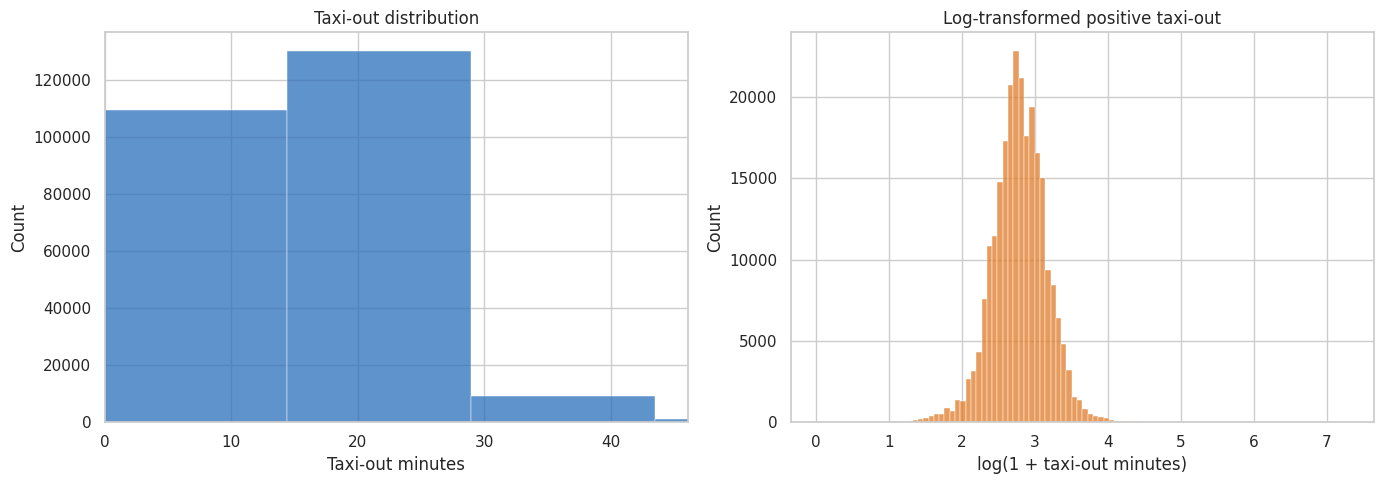

In [17]:
# Target distribution
# Summarise the full departure target and show its operational centre and long right tail.

quantile_probs = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999]
overall_exprs = [
    pl.len().alias("rows"), pl.col(TARGET).count().alias("non_null_target"),
    pl.col(TARGET).mean().alias("mean_sec"), pl.col(TARGET).median().alias("median_sec"),
    pl.col(TARGET).std().alias("std_sec"), pl.col(TARGET).min().alias("min_sec"),
    pl.col(TARGET).max().alias("max_sec"), (pl.col(TARGET) < 0).sum().alias("negative"),
    (pl.col(TARGET) == 0).sum().alias("zero"),
    *[pl.col(TARGET).quantile(q, interpolation="nearest").alias(f"p{q*100:g}_sec") for q in quantile_probs],
]
overall_target_summary = departures.select(overall_exprs).collect()
display(overall_target_summary)
overall_target_summary.write_csv(TABLE_DIR / "target_summary_overall_departures.csv")

plot_sample = (
    departures.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)) & pl.col(TARGET).is_not_null())
    .select("movement_airport", TARGET).collect().sample(fraction=0.12, seed=RANDOM_SEED).to_pandas()
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(plot_sample[TARGET] / 60, bins=100, ax=axes[0], color="#2a6fbb")
axes[0].set(title="Taxi-out distribution", xlabel="Taxi-out minutes",
            xlim=(0, np.nanpercentile(plot_sample[TARGET] / 60, 99.5)))
positive_minutes = plot_sample.loc[plot_sample[TARGET] > 0, TARGET] / 60
sns.histplot(np.log1p(positive_minutes), bins=100, ax=axes[1], color="#e07a25")
axes[1].set(title="Log-transformed positive taxi-out", xlabel="log(1 + taxi-out minutes)")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "taxi_out_distribution.png", dpi=160); plt.show()

movement_airport,rows,mean_sec,median_sec,std_sec,min_sec,max_sec,negative,zero,p1_sec,p5_sec,p25_sec,p50_sec,p75_sec,p95_sec,p99_sec,p99.5_sec,p99.9_sec
str,u32,f64,f64,f64,i32,i32,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""EDDF""",230141,863.478155,837.0,329.788602,2,6907,0,0,246.0,376.0,649.0,837.0,1048.0,1399.0,1819.0,2106.0,2927.0
"""EDDM""",167334,811.911889,774.0,301.754971,2,6899,0,0,348.0,472.0,612.0,774.0,911.0,1320.0,1921.0,2220.0,3009.0
"""EGLL""",239546,1364.239319,1319.0,421.784293,9,11452,0,0,667.0,835.0,1088.0,1319.0,1561.0,1989.0,2701.0,3189.0,4747.0
"""EHAM""",247951,784.559748,742.0,318.459805,-4,11032,3,0,173.0,382.0,579.0,742.0,943.0,1309.0,1775.0,2102.0,2934.0
"""LEBL""",179705,956.549356,906.0,330.914415,-8,3604,5,0,391.0,530.0,714.0,906.0,1161.0,1501.0,1962.0,2257.0,2963.0
"""LEMD""",212242,1014.709982,985.0,312.549241,39,3598,0,0,397.0,568.0,807.0,985.0,1186.0,1559.0,1932.0,2125.0,2704.0
"""LFPG""",239552,1019.52331,954.0,452.990206,-12,84240,61,4,429.0,592.0,777.0,954.0,1151.0,1681.0,2409.0,2828.0,4023.0
"""LIRF""",160704,1194.607527,1025.0,1331.956605,49,131167,0,0,417.0,601.0,834.0,1025.0,1318.0,2090.0,4019.0,5524.0,11573.0
"""LSZH""",134907,740.51365,711.0,385.381431,-12,87341,298,15,190.0,296.0,568.0,711.0,878.0,1240.0,1707.0,1929.0,2504.0


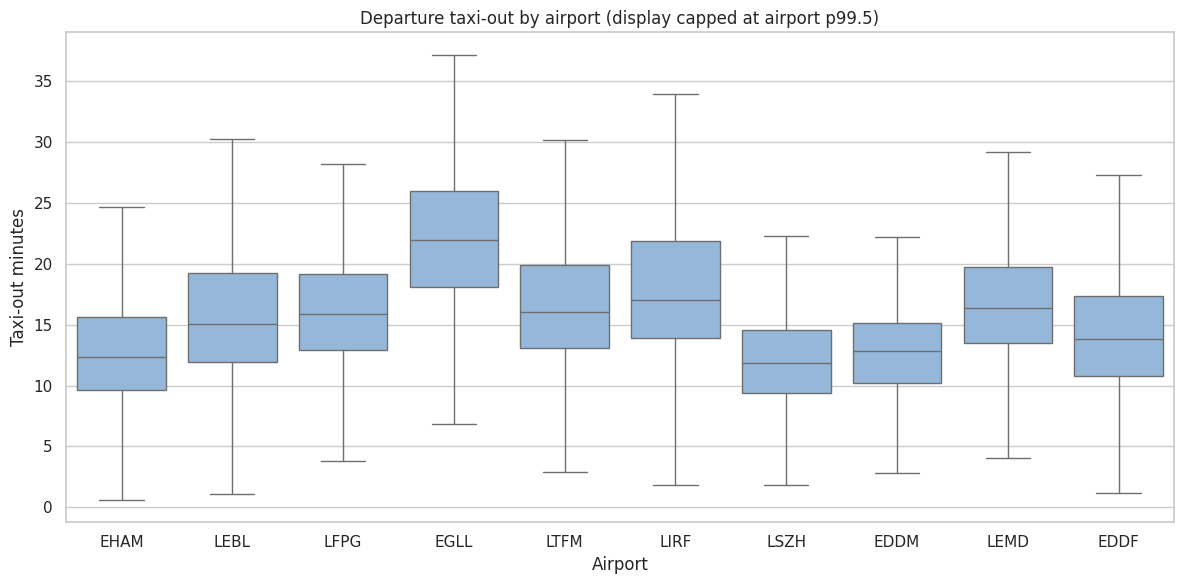

In [18]:
# Airport comparisons
# Compare target location, spread, quantiles, and readable p99.5-capped boxplots across the 10 airports.

airport_exprs = [
    pl.len().alias("rows"), pl.col(TARGET).mean().alias("mean_sec"),
    pl.col(TARGET).median().alias("median_sec"), pl.col(TARGET).std().alias("std_sec"),
    pl.col(TARGET).min().alias("min_sec"), pl.col(TARGET).max().alias("max_sec"),
    (pl.col(TARGET) < 0).sum().alias("negative"), (pl.col(TARGET) == 0).sum().alias("zero"),
    *[pl.col(TARGET).quantile(q, interpolation="nearest").alias(f"p{q*100:g}_sec") for q in quantile_probs],
]
airport_target_summary = (
    departures.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
    .group_by("movement_airport").agg(airport_exprs).sort("movement_airport").collect()
)
display(airport_target_summary)
airport_target_summary.write_csv(TABLE_DIR / "target_summary_by_airport_departures.csv")

airport_caps = plot_sample.groupby("movement_airport")[TARGET].quantile(0.995)
box_data = plot_sample[plot_sample[TARGET] <= plot_sample["movement_airport"].map(airport_caps)].copy()
box_data["taxi_minutes"] = box_data[TARGET] / 60
plt.figure(figsize=(12, 6))
sns.boxplot(data=box_data, x="movement_airport", y="taxi_minutes", color="#89b9e5", showfliers=False)
plt.title("Departure taxi-out by airport (display capped at airport p99.5)")
plt.xlabel("Airport"); plt.ylabel("Taxi-out minutes"); plt.tight_layout()
plt.savefig(FIGURE_DIR / "taxi_out_by_airport.png", dpi=160); plt.show()

,flag,records_flagged,percentage_of_departures,treatment
0,flag_above_airport_p99_5,10411,0.499317,FLAG_FOR_SENSITIVITY_ANALYSIS
1,flag_above_airport_month_p99_5,10394,0.498502,FLAG_FOR_SENSITIVITY_ANALYSIS
2,flag_airport_iqr_outlier,18433,0.884057,FLAG_FOR_SENSITIVITY_ANALYSIS
3,flag_robust_mad_outlier,18316,0.878445,FLAG_FOR_SENSITIVITY_ANALYSIS
4,flag_extreme_taxi,22149,1.062278,FLAG_FOR_SENSITIVITY_ANALYSIS


MVT_ID_mvt,source_month,movement_airport,BLOCK_TIME_UTC_mvt,MVT_TIME_UTC_mvt,TAXITIME_SEC_mvt,airport_p99_5_sec,airport_month_p99_5_sec,airport_iqr_upper_fence_sec,robust_mad_score,flag_above_airport_p99_5,flag_above_airport_month_p99_5,flag_airport_iqr_outlier,flag_robust_mad_outlier,flag_extreme_taxi
f64,str,str,"datetime[μs, UTC]","datetime[μs, UTC]",i32,f64,f64,f64,f64,bool,bool,bool,bool,bool
1.83903219e8,"""2025-02""","""LIRF""",2025-02-10 05:24:56 UTC,2025-02-11 17:51:03 UTC,131167,5524.0,4614.0,2770.0,370.383034,true,true,true,true,true
1.9019954e8,"""2025-06""","""LIRF""",2025-06-24 15:29:54 UTC,2025-06-25 16:03:06 UTC,88392,5524.0,6532.0,2770.0,248.645745,true,true,true,true,true
1.92626268e8,"""2025-07""","""LIRF""",2025-07-20 08:00:04 UTC,2025-07-21 08:28:56 UTC,88132,5524.0,8092.0,2770.0,247.905787,true,true,true,true,true
2.01198951e8,"""2025-12""","""LIRF""",2025-12-27 18:14:57 UTC,2025-12-28 18:35:02 UTC,87605,5524.0,5350.0,2770.0,246.405949,true,true,true,true,true
2.00300302e8,"""2025-11""","""LIRF""",2025-11-11 11:55:01 UTC,2025-11-12 12:14:59 UTC,87598,5524.0,4251.0,2770.0,246.386027,true,true,true,true,true
1.96129531e8,"""2025-09""","""LIRF""",2025-09-27 22:18:58 UTC,2025-09-28 22:38:01 UTC,87543,5524.0,5995.0,2770.0,246.229498,true,true,true,true,true
2.00297323e8,"""2025-11""","""LIRF""",2025-11-03 13:04:00 UTC,2025-11-04 13:22:00 UTC,87480,5524.0,4251.0,2770.0,246.0502,true,true,true,true,true
1.92615553e8,"""2025-07""","""LIRF""",2025-07-02 16:44:59 UTC,2025-07-03 17:01:00 UTC,87361,5524.0,8092.0,2770.0,245.711527,true,true,true,true,true
1.88253302e8,"""2025-05""","""LSZH""",2025-05-13 14:39:58 UTC,2025-05-14 14:55:39 UTC,87341,1929.0,1669.0,1806.0,379.423769,true,true,true,true,true


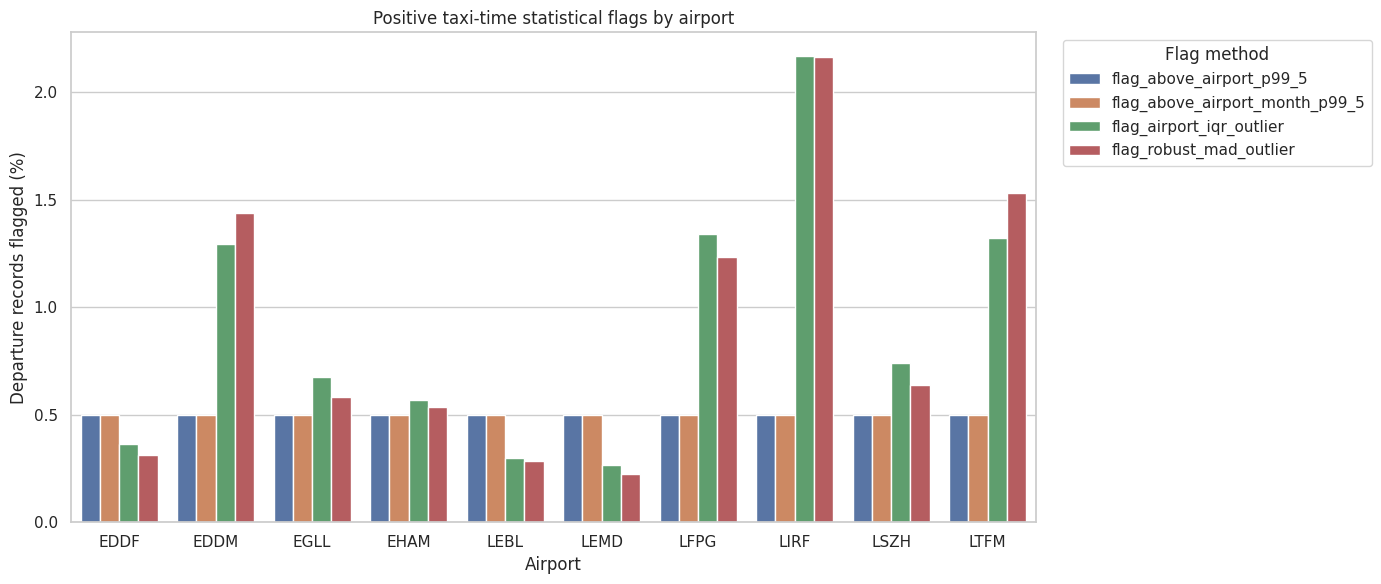

Operational threshold: None
Rows flagged by at least one statistical method: 22,149


In [19]:
# Extreme values
# Apply airport p99.5, airport-month p99.5, conservative IQR, and robust MAD rules.

OPERATIONAL_MAX_TAXI_SEC = None  # Set only when a documented domain limit is agreed.
ROBUST_MAD_THRESHOLD = 5.0

positive_departures = departures.filter(
    pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)) &
    (pl.col(TARGET) > 0)
)

airport_extreme_thresholds = (
    positive_departures.group_by("movement_airport")
    .agg([
        pl.col(TARGET).quantile(0.25, interpolation="nearest").alias("airport_q1_sec"),
        pl.col(TARGET).median().alias("airport_median_sec"),
        pl.col(TARGET).quantile(0.75, interpolation="nearest").alias("airport_q3_sec"),
        pl.col(TARGET).quantile(0.995, interpolation="nearest").alias("airport_p99_5_sec"),
    ])
    .with_columns(
        (pl.col("airport_q3_sec") + 3 * (pl.col("airport_q3_sec") - pl.col("airport_q1_sec")))
        .alias("airport_iqr_upper_fence_sec")
    )
)

airport_month_extreme_thresholds = (
    positive_departures.group_by("movement_airport", "source_month")
    .agg(
        pl.col(TARGET).quantile(0.995, interpolation="nearest")
        .alias("airport_month_p99_5_sec")
    )
)

airport_mad = (
    positive_departures.join(airport_extreme_thresholds, on="movement_airport", how="left")
    .with_columns((pl.col(TARGET) - pl.col("airport_median_sec")).abs().alias("absolute_median_deviation_sec"))
    .group_by("movement_airport")
    .agg(pl.col("absolute_median_deviation_sec").median().alias("airport_mad_sec"))
)

operational_flag_expression = (
    pl.lit(None, dtype=pl.Boolean)
    if OPERATIONAL_MAX_TAXI_SEC is None
    else (pl.col(TARGET) > OPERATIONAL_MAX_TAXI_SEC).fill_null(False)
)

extreme_flagged_departures = (
    departures.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
    .join(airport_extreme_thresholds, on="movement_airport", how="left")
    .join(airport_month_extreme_thresholds, on=["movement_airport", "source_month"], how="left")
    .join(airport_mad, on="movement_airport", how="left")
    .with_columns([
        pl.when(pl.col("airport_mad_sec") > 0)
        .then(0.6745 * (pl.col(TARGET) - pl.col("airport_median_sec")) / pl.col("airport_mad_sec"))
        .otherwise(None)
        .alias("robust_mad_score"),
        ((pl.col(TARGET) > 0) & (pl.col(TARGET) > pl.col("airport_p99_5_sec")))
        .fill_null(False).alias("flag_above_airport_p99_5"),
        ((pl.col(TARGET) > 0) & (pl.col(TARGET) > pl.col("airport_month_p99_5_sec")))
        .fill_null(False).alias("flag_above_airport_month_p99_5"),
        ((pl.col(TARGET) > 0) & (pl.col(TARGET) > pl.col("airport_iqr_upper_fence_sec")))
        .fill_null(False).alias("flag_airport_iqr_outlier"),
        operational_flag_expression.alias("flag_operationally_implausible"),
    ])
    .with_columns(
        ((pl.col(TARGET) > 0) & (pl.col("robust_mad_score") > ROBUST_MAD_THRESHOLD))
        .fill_null(False).alias("flag_robust_mad_outlier")
    )
    .with_columns(
        pl.any_horizontal([
            pl.col("flag_above_airport_p99_5"),
            pl.col("flag_above_airport_month_p99_5"),
            pl.col("flag_airport_iqr_outlier"),
            pl.col("flag_robust_mad_outlier"),
        ]).alias("flag_extreme_taxi")
    )
)

extreme_flag_columns = [
    "flag_above_airport_p99_5",
    "flag_above_airport_month_p99_5",
    "flag_airport_iqr_outlier",
    "flag_robust_mad_outlier",
    "flag_extreme_taxi",
]

extreme_counts_row = extreme_flagged_departures.select(
    [pl.len().alias("departure_rows")] + [pl.col(c).sum().alias(c) for c in extreme_flag_columns]
).collect().row(0, named=True)

extreme_taxi_summary = pd.DataFrame([
    {
        "flag": flag,
        "records_flagged": int(extreme_counts_row[flag]),
        "percentage_of_departures": 100 * int(extreme_counts_row[flag]) / int(extreme_counts_row["departure_rows"]),
        "treatment": "FLAG_FOR_SENSITIVITY_ANALYSIS",
    }
    for flag in extreme_flag_columns
])

extreme_taxi_by_airport_month = (
    extreme_flagged_departures.group_by("source_month", "movement_airport")
    .agg([pl.len().alias("departure_rows")] + [pl.col(c).sum().alias(c) for c in extreme_flag_columns])
    .sort("source_month", "movement_airport")
    .collect()
)

extreme_taxi_examples = (
    extreme_flagged_departures.filter(pl.col("flag_extreme_taxi"))
    .select([
        "MVT_ID_mvt", "source_month", "movement_airport", "BLOCK_TIME_UTC_mvt",
        "MVT_TIME_UTC_mvt", TARGET, "airport_p99_5_sec", "airport_month_p99_5_sec",
        "airport_iqr_upper_fence_sec", "robust_mad_score", *extreme_flag_columns,
    ])
    .sort(TARGET, descending=True)
    .limit(200)
    .collect()
)

flag_export_columns = [
    "MVT_ID_mvt", "source_month", "movement_airport", TARGET,
    "airport_p99_5_sec", "airport_month_p99_5_sec", "airport_iqr_upper_fence_sec",
    "airport_mad_sec", "robust_mad_score", "flag_operationally_implausible",
    *extreme_flag_columns,
]
extreme_flagged_departures.select(flag_export_columns).sink_parquet(
    TABLE_DIR / "taxi_extreme_flags.parquet", compression="zstd"
)

airport_extreme_thresholds.collect().write_csv(TABLE_DIR / "extreme_thresholds_by_airport.csv")
airport_month_extreme_thresholds.collect().write_csv(TABLE_DIR / "extreme_thresholds_by_airport_month.csv")
extreme_taxi_summary.to_csv(TABLE_DIR / "extreme_taxi_summary.csv", index=False)
extreme_taxi_by_airport_month.write_csv(TABLE_DIR / "extreme_taxi_by_airport_month.csv")
extreme_taxi_examples.write_csv(TABLE_DIR / "extreme_taxi_examples.csv")

display(extreme_taxi_summary)
display(extreme_taxi_examples.head(20))

airport_extreme_plot = (
    extreme_flagged_departures.group_by("movement_airport")
    .agg([pl.len().alias("departure_rows")] + [pl.col(c).sum().alias(c) for c in extreme_flag_columns[:-1]])
    .sort("movement_airport")
    .collect().to_pandas()
)
for flag in extreme_flag_columns[:-1]:
    airport_extreme_plot[flag] = 100 * airport_extreme_plot[flag] / airport_extreme_plot["departure_rows"]

airport_extreme_long = airport_extreme_plot.melt(
    id_vars=["movement_airport", "departure_rows"],
    value_vars=extreme_flag_columns[:-1],
    var_name="flag_method", value_name="flagged_pct",
)
plt.figure(figsize=(14, 6))
sns.barplot(data=airport_extreme_long, x="movement_airport", y="flagged_pct", hue="flag_method")
plt.title("Positive taxi-time statistical flags by airport")
plt.xlabel("Airport")
plt.ylabel("Departure records flagged (%)")
plt.legend(title="Flag method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "extreme_taxi_flags_by_airport.png", dpi=160)
plt.show()

print("Operational threshold:", OPERATIONAL_MAX_TAXI_SEC)
print("Rows flagged by at least one statistical method:", f"{int(extreme_counts_row['flag_extreme_taxi']):,}")

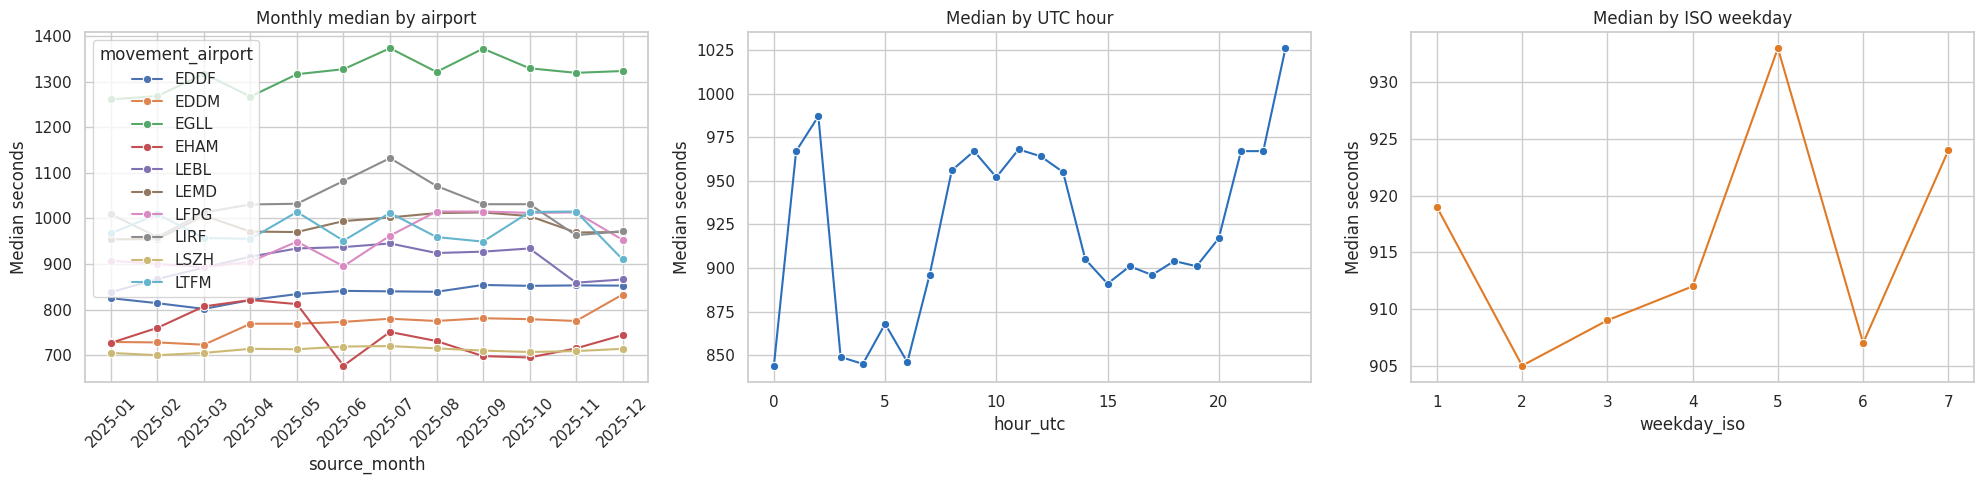

In [20]:
# Temporal patterns
# Compare monthly, UTC-hour, and weekday taxi-out medians and volumes using the full departure population.

temporal_patterns = (
    departures.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
    .with_columns([
        pl.col("BLOCK_TIME_UTC_mvt").dt.hour().alias("hour_utc"),
        pl.col("BLOCK_TIME_UTC_mvt").dt.weekday().alias("weekday_iso"),
    ])
)

monthly_taxi = temporal_patterns.group_by("source_month", "movement_airport").agg([
    pl.len().alias("departures"), pl.col(TARGET).median().alias("median_sec")
]).sort("source_month", "movement_airport").collect()
hourly_taxi = temporal_patterns.group_by("hour_utc").agg([
    pl.len().alias("departures"), pl.col(TARGET).median().alias("median_sec")
]).sort("hour_utc").collect()
weekday_taxi = temporal_patterns.group_by("weekday_iso").agg([
    pl.len().alias("departures"), pl.col(TARGET).median().alias("median_sec")
]).sort("weekday_iso").collect()

monthly_taxi.write_csv(TABLE_DIR / "taxi_out_monthly_patterns.csv")
hourly_taxi.write_csv(TABLE_DIR / "taxi_out_hourly_patterns.csv")
weekday_taxi.write_csv(TABLE_DIR / "taxi_out_weekday_patterns.csv")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.lineplot(data=monthly_taxi.to_pandas(), x="source_month", y="median_sec",
             hue="movement_airport", marker="o", ax=axes[0])
axes[0].tick_params(axis="x", rotation=45); axes[0].set(title="Monthly median by airport", ylabel="Median seconds")
sns.lineplot(data=hourly_taxi.to_pandas(), x="hour_utc", y="median_sec", marker="o", ax=axes[1], color="#2a6fbb")
axes[1].set(title="Median by UTC hour", ylabel="Median seconds")
sns.lineplot(data=weekday_taxi.to_pandas(), x="weekday_iso", y="median_sec", marker="o", ax=axes[2], color="#e07a25")
axes[2].set(title="Median by ISO weekday", ylabel="Median seconds")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "taxi_out_temporal_patterns.png", dpi=160); plt.show()

In [21]:
# REPORTING — Automated checks
# Translate the evidence into explicit PASS, WARNING, and FAIL quality gates.

key = taxi_consistency.row(0, named=True)
ids = id_integrity.row(0, named=True)
null_count_lookup = overall_missingness.set_index("column")["null_count"]
total_null_flight_ids = int(null_count_lookup["FLIGHT_ID_mvt"])
extreme_target_count = int(extreme_counts_row["flag_extreme_taxi"])

phase_target_counts = {row["phase_standardised"]: row for row in target_missingness_by_phase.to_dicts()}
departure_target_nulls = int(phase_target_counts["DEP"]["missing_target"])
arrival_target_nulls = int(phase_target_counts["ARR"]["missing_target"])
departure_rows = int(phase_target_counts["DEP"]["rows"])
arrival_rows = int(phase_target_counts["ARR"]["rows"])

def check(name, condition, severity_if_false, evidence):
    return {
        "check": name,
        "result": "PASS" if bool(condition) else severity_if_false,
        "evidence": str(evidence),
    }

required_missing = sorted(REQUIRED_COLUMNS - set(raw_schema.names()))
timezone_ok = all("UTC" in str(raw_schema[c]) for c in ["BLOCK_TIME_UTC_mvt", "MVT_TIME_UTC_mvt"])
invalid_documented_categories = int(categorical_domain_validation["invalid_count"].sum())

quality_checks = pd.DataFrame([
    check("Exactly 12 training months found", len(training_files) == 12 and observed_months == EXPECTED_MONTHS,
          "FAIL", f"files={len(training_files)}; missing_months={sorted(EXPECTED_MONTHS-observed_months)}"),
    check("All required columns present", not required_missing, "FAIL", f"missing={required_missing}"),
    check("All 10 target airports observed", observed_target_airports == EXPECTED_AIRPORTS, "FAIL",
          f"missing={sorted(EXPECTED_AIRPORTS-observed_target_airports)}"),
    check("Monthly schemas consistent", schema_issues.empty, "FAIL", f"differences={len(schema_issues)}"),
    check("Documented categorical domains respected", invalid_documented_categories == 0, "WARNING",
          f"invalid_values_count={invalid_documented_categories}"),
    check("Movement timestamps use UTC", timezone_ok, "FAIL",
          f"block={raw_schema['BLOCK_TIME_UTC_mvt']}; movement={raw_schema['MVT_TIME_UTC_mvt']}"),
    check("Departure records exist", departure_rows > 0, "FAIL", f"departures={departure_rows:,}"),
    check("Departure taxi-out target is complete", departure_target_nulls == 0, "FAIL",
          f"missing_DEP={departure_target_nulls:,}; missing_ARR={arrival_target_nulls:,}"),
    check("MVT_ID is globally unique", int(ids["duplicate_id_excess_rows"]) == 0, "FAIL",
          f"excess_rows={int(ids['duplicate_id_excess_rows']):,}"),
    check("Exact duplicate rows are zero", exact_duplicate_rows == 0, "FAIL",
          f"exact_duplicate_rows={exact_duplicate_rows:,} (derived from MVT_ID_mvt uniqueness)"),
    check("MVT_ID values are integer-valued", int(ids["non_integer_valued_mvt_ids"]) == 0, "FAIL",
          f"non_integer={int(ids['non_integer_valued_mvt_ids']):,}"),
    check("No negative departure targets", int(key["negative_targets"]) == 0, "WARNING",
          f"negative={int(key['negative_targets']):,}"),
    check("Departure target matches official timestamp formula within 1 sec", int(key["mismatches_over_1_second"]) == 0,
          "WARNING", f"mismatches={int(key['mismatches_over_1_second']):,}"),
    check("No missing flight linkage ID", total_null_flight_ids == 0, "WARNING",
          f"missing_flight_id={total_null_flight_ids:,}"),
    check("No military labels remain in joined NM classifications", military_union_count == 0, "WARNING",
          f"FLIGHT_TYPE_flt_M={military_flight_type_count:,}; MARKET_SEGMENT_flt_Military={military_market_segment_count:,}; union={military_union_count:,}"),
    check("Positive taxi-time extremes explicitly flagged", "flag_extreme_taxi" in extreme_flagged_departures.collect_schema(),
          "FAIL", f"combined_flagged={extreme_target_count:,}; methods=4"),
])
display(quality_checks)
quality_checks.to_csv(TABLE_DIR / "quality_checks.csv", index=False)

,check,result,evidence
0,Exactly 12 training months found,PASS,files=12; missing_months=[]
1,All required columns present,PASS,missing=[]
2,All 10 target airports observed,PASS,missing=[]
3,Monthly schemas consistent,PASS,differences=0
4,Documented categorical domains respected,PASS,invalid_values_count=0
5,Movement timestamps use UTC,PASS,"block=Datetime(time_unit='us', time_zone='UTC'..."
6,Departure records exist,PASS,"departures=2,085,047"
7,Departure taxi-out target is complete,PASS,missing_DEP=0; missing_ARR=1
8,MVT_ID is globally unique,PASS,excess_rows=0
9,Exact duplicate rows are zero,PASS,exact_duplicate_rows=0 (derived from MVT_ID_mv...


In [24]:
import subprocess
import sys

# Profiling
# Create the required stratified `fg-data-profiling` report and record the exact package versions used.

RUN_FG_DATA_PROFILE = True
PROFILE_SAMPLE_PER_GROUP = 250
PROFILE_PATH = PROFILE_DIR / "profiling_report.html"

if not RUN_FG_DATA_PROFILE:
    raise RuntimeError(
        "The fg-data-profiling report is a required deliverable. "
        "Keep RUN_FG_DATA_PROFILE=True for the final September 20 run."
    )

if importlib.util.find_spec("data_profiling") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "fg-data-profiling"])

from data_profiling import ProfileReport

# Sampled by (month, airport, phase) rather than departures-only, so the raw-data profile
# required by the Role 1 brief covers both ARR and DEP movements. Target-distribution work
# elsewhere in the notebook stays departure-only, since TAXITIME_SEC_mvt means taxi-in for
# arrivals, not taxi-out.
profile_sample_pl = (
    data.filter(pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)))
        .group_by("source_month", "movement_airport", "phase_standardised")
        .map_groups(
            lambda frame: frame.sample(
                n=min(PROFILE_SAMPLE_PER_GROUP, frame.height),
                seed=RANDOM_SEED,
            ),
            schema=None,
        )
        .collect()
)

profile_group_coverage = (
    profile_sample_pl.group_by("source_month", "movement_airport", "phase_standardised")
                     .len()
                     .sort("source_month", "movement_airport", "phase_standardised")
)

expected_profile_groups = len(EXPECTED_MONTHS) * len(EXPECTED_AIRPORTS) * 2
if profile_group_coverage.height != expected_profile_groups:
    raise RuntimeError(
        f"Expected {expected_profile_groups} airport-month-phase groups in the profile sample "
        f"but found {profile_group_coverage.height}. Check dataset coverage."
    )

profile_sample = profile_sample_pl.to_pandas()

profile = ProfileReport(
    profile_sample,
    title="PRC Data Challenge 2026 \u2014 September 20 Stratified Training Profile",
    explorative=True,
    minimal=True,
    dataset={
        "description": (
            "Stratified sample of both arrival and departure records across all 10 "
            "competition airports and all 12 training months. Official counts are "
            "calculated from the full dataset elsewhere in the EDA notebook."
        )
    },
)
profile.to_file(PROFILE_PATH)

if not PROFILE_PATH.exists() or PROFILE_PATH.stat().st_size == 0:
    raise RuntimeError("The required fg-data-profiling HTML report was not created.")

print(f"Profile sample rows: {len(profile_sample):,}")
print(f"Airport-month-phase groups represented: {profile_group_coverage.height}/{expected_profile_groups}")
print(f"Required profiling report created: {PROFILE_PATH}")
display(FileLink(str(PROFILE_PATH)))


try:
    import data_profiling
    data_profiling_version = getattr(data_profiling, "__version__", "unknown")
except ImportError:
    data_profiling_version = "not installed"

package_versions = pd.DataFrame([{
    "python": platform.python_version(),
    "polars": pl.__version__,
    "pyarrow": pa.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "fg_data_profiling": data_profiling_version,
}])
display(package_versions)
package_versions.to_csv(TABLE_DIR / "package_versions.csv", index=False)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 34/34 [00:05<00:00,  6.77it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profile sample rows: 60,000
Airport-month-phase groups represented: 240/240
Required profiling report created: reports/sep20_eda/profiling/profiling_report.html


/content/reports/sep20_eda/profiling/profiling_report.html

,python,polars,pyarrow,pandas,matplotlib,seaborn,fg_data_profiling
0,3.13.15,1.35.2,23.0.1,2.2.3,3.10.0,0.13.2,4.20.0


In [25]:
# Reports
# Build the per-airport QA table, anomaly register, and self-contained Markdown EDA report from computed evidence.

def dataframe_to_markdown(df: pd.DataFrame) -> str:
    """Render a small pandas DataFrame as a GitHub-flavoured Markdown table with no extra dependency."""
    headers = list(df.columns)
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    for _, row in df.iterrows():
        lines.append("| " + " | ".join(str(v) for v in row) + " |")
    return "\n".join(lines)


airport_missingness = (
    data.filter(
        pl.col("movement_airport").is_in(sorted(EXPECTED_AIRPORTS)) &
        (pl.col("phase_standardised") == "DEP")
    )
    .with_columns([
        (pl.col(TARGET) < 0).alias("is_negative_target"),
        (pl.col(TARGET) == 0).alias("is_zero_target"),
    ])
    .group_by("movement_airport")
    .agg([
        pl.len().alias("departure_rows"),
        pl.col("BLOCK_TIME_UTC_mvt").null_count().alias("missing_block"),
        pl.col("MVT_TIME_UTC_mvt").null_count().alias("missing_movement"),
        pl.col("FLIGHT_ID_mvt").null_count().alias("missing_flight_id"),
        pl.col("is_negative_target").sum().alias("negative_targets"),
        pl.col("is_zero_target").sum().alias("zero_targets"),
    ])
    .collect()
)

airport_extreme_counts = (
    extreme_taxi_by_airport_month
    .group_by("movement_airport")
    .agg(pl.col("flag_extreme_taxi").sum().alias("extreme_flagged"))
)

per_airport_summary = (
    airport_missingness.join(airport_extreme_counts, on="movement_airport", how="left")
    .with_columns([
        (100 * pl.col("missing_block") / pl.col("departure_rows")).round(3).alias("missing_block_pct"),
        (100 * pl.col("missing_movement") / pl.col("departure_rows")).round(3).alias("missing_movement_pct"),
        (100 * pl.col("missing_flight_id") / pl.col("departure_rows")).round(3).alias("missing_flight_id_pct"),
        (100 * pl.col("negative_targets") / pl.col("departure_rows")).round(4).alias("negative_target_pct"),
        (100 * pl.col("zero_targets") / pl.col("departure_rows")).round(4).alias("zero_target_pct"),
        (100 * pl.col("extreme_flagged") / pl.col("departure_rows")).round(3).alias("extreme_flagged_pct"),
    ])
    .sort("movement_airport")
    .select([
        "movement_airport", "departure_rows",
        "missing_block_pct", "missing_movement_pct", "missing_flight_id_pct",
        "negative_target_pct", "zero_target_pct", "extreme_flagged_pct",
    ])
    .rename({
        "movement_airport": "Airport",
        "departure_rows": "Departures",
        "missing_block_pct": "Missing block %",
        "missing_movement_pct": "Missing movement %",
        "missing_flight_id_pct": "Missing FLIGHT_ID %",
        "negative_target_pct": "Negative target %",
        "zero_target_pct": "Zero target %",
        "extreme_flagged_pct": "Extreme-flagged %",
    })
)

display(per_airport_summary)
per_airport_summary.write_csv(TABLE_DIR / "per_airport_summary.csv")

per_airport_summary_pd = per_airport_summary.to_pandas()
per_airport_summary_pd["Departures"] = per_airport_summary_pd["Departures"].map("{:,}".format)
for pct_col in ["Missing block %", "Missing movement %", "Missing FLIGHT_ID %",
                "Negative target %", "Zero target %", "Extreme-flagged %"]:
    per_airport_summary_pd[pct_col] = per_airport_summary_pd[pct_col].map(lambda v: f"{v:.3f}")

airport_table_markdown = dataframe_to_markdown(per_airport_summary_pd)
print(airport_table_markdown)


# Military counts and audit were computed once in Section 15.
block_nulls = int(null_count_lookup["BLOCK_TIME_UTC_mvt"])

anomaly_register = pd.DataFrame([
    ["DQ-001", "Missing block timestamp", "BLOCK_TIME_UTC_mvt", block_nulls, 100*block_nulls/total_rows, "Investigate source row; preserve original", "INVESTIGATE", "Role 1 + Role 2"],
    ["DQ-002", "Missing arrival taxi-in target; departure target complete", TARGET, arrival_target_nulls, 100*arrival_target_nulls/arrival_rows, "No impact on departure model", "KEEP", "Role 1"],
    ["DQ-003", "Negative departure taxi-out time", TARGET, int(key["negative_targets"]), 100*int(key["negative_targets"])/departure_rows, "Quarantine for investigation; never take absolute value", "INVESTIGATE", "Role 1"],
    ["DQ-004", "Zero departure taxi-out time", TARGET, int(key["zero_targets"]), 100*int(key["zero_targets"])/departure_rows, "Check concentration by airport/month", "INVESTIGATE", "Role 1"],
    ["DQ-005", "Departure target differs from official formula by >1 second", TARGET, int(key["mismatches_over_1_second"]), 100*int(key["mismatches_over_1_second"])/departure_rows, "Investigate only if non-zero", "KEEP", "Role 1"],
    ["DQ-006", "Repeated movement ID excess rows", "MVT_ID_mvt", int(ids["duplicate_id_excess_rows"]), 100*int(ids["duplicate_id_excess_rows"])/total_rows, "Classify before deduplication", "INVESTIGATE", "Role 1 + Role 2"],
    ["DQ-007", "Missing linked NM flight ID", "FLIGHT_ID_mvt", total_null_flight_ids, 100*total_null_flight_ids/total_rows, "Assess feature availability; do not discard automatically", "INVESTIGATE", "Role 2"],
    ["DQ-008", "Positive taxi time flagged by ≥1 extreme rule", TARGET, extreme_target_count, 100*extreme_target_count/departure_rows, "Retain and test in sensitivity analysis", "FLAG_FOR_SENSITIVITY_ANALYSIS", "Roles 1, 2, 5"],
    ["DQ-009", "Military classification remains in joined NM fields", "FLIGHT_TYPE_flt / MARKET_SEGMENT_flt", military_union_count, 100*military_union_count/total_rows, "Ask organiser; do not delete automatically", "INVESTIGATE", "Roles 1, 2"],
], columns=["anomaly_id", "issue", "affected_column", "records_affected", "percentage_affected",
            "recommended_next_step", "preliminary_treatment", "owner"])
anomaly_register["date_detected_utc"] = datetime.now(timezone.utc).date().isoformat()
anomaly_register["status"] = "OPEN"
display(anomaly_register)
anomaly_register.to_csv(TABLE_DIR / "anomaly_register.csv", index=False)

overall = overall_target_summary.row(0, named=True)
anomaly_text = "\n".join(
    f"- **{row.anomaly_id} — {row.issue}:** {int(row.records_affected):,} records "
    f"({row.percentage_affected:.4f}%)."
    for row in anomaly_register.itertuples(index=False)
)

report = f'''# PRC Data Challenge 2026 — Initial EDA Report

## Scope

- **Training data:** {len(training_files)} monthly files covering January–December 2025.
- **Records:** {total_rows:,} movements — {departure_rows:,} departures and {arrival_rows:,} arrivals.
- **Coverage:** all {len(observed_target_airports)} target airports and all {len(observed_months)} expected months are present.
- **Analysis target:** departure taxi-out only; arrivals are retained for general quality checks.
- **Leakage control:** ranking and submission data are excluded from all EDA rules and thresholds.

## Main data-quality findings

- Monthly schemas are consistent and all required columns are present.
- `MVT_ID_mvt` is complete and globally unique; no duplicate movement records were identified.
- Movement timestamps are stored as UTC datetimes.
- Departure taxi-out targets are complete: {departure_target_nulls:,} missing values.
- One block timestamp and one arrival taxi-in target are missing.
- The supplied departure target matches `MVT_TIME_UTC_mvt - BLOCK_TIME_UTC_mvt` for every recalculable departure.
- Missing `FLIGHT_ID_mvt`: {total_null_flight_ids:,} records ({100*total_null_flight_ids/total_rows:.4f}%).
- Military classifications remain in {military_union_count:,} joined flight records and require clarification.

## Taxi-out findings

- **Median:** {float(overall['median_sec'])/60:.2f} minutes.
- **Maximum:** {float(overall['max_sec'])/60:.2f} minutes.
- **Negative targets:** {int(key['negative_targets']):,}.
- **Zero targets:** {int(key['zero_targets']):,}.
- **Positive statistical extremes:** {extreme_target_count:,} departures ({100*extreme_target_count/departure_rows:.3f}%).
- Extreme records are flagged for sensitivity analysis; they are not automatically removed.

## Per-airport snapshot

{airport_table_markdown}

`Extreme-flagged %` is the union of the airport p99.5, airport-month p99.5, IQR and robust MAD methods.

## Anomaly summary

{anomaly_text}

## Overall conclusion

- The training data are structurally complete and suitable for continued analysis and baseline modelling.
- Negative, zero and statistically extreme targets remain flagged until final cleaning decisions are agreed.
- Missing flight linkage and military classifications should be treated as investigation flags, not automatic exclusion rules.
'''

report_path = OUTPUT_DIR / "initial_eda_report.md"
report_path.write_text(report, encoding="utf-8")
display(Markdown(report))
print("Saved:", report_path)

Airport,Departures,Missing block %,Missing movement %,Missing FLIGHT_ID %,Negative target %,Zero target %,Extreme-flagged %
str,u32,f64,f64,f64,f64,f64,f64
"""EDDF""",230141,0.0,0.0,0.85,0.0,0.0,0.659
"""EDDM""",167334,0.0,0.0,0.603,0.0,0.0,1.508
"""EGLL""",239546,0.0,0.0,0.59,0.0,0.0,0.711
"""EHAM""",247951,0.0,0.0,1.647,0.0012,0.0,0.802
"""LEBL""",179705,0.0,0.0,1.033,0.0028,0.0,0.654
"""LEMD""",212242,0.0,0.0,0.442,0.0,0.0,0.544
"""LFPG""",239552,0.0,0.0,1.572,0.0255,0.0017,1.349
"""LIRF""",160704,0.0,0.0,0.925,0.0,0.0,2.17
"""LSZH""",134907,0.0,0.0,1.698,0.2209,0.0111,0.855


| Airport | Departures | Missing block % | Missing movement % | Missing FLIGHT_ID % | Negative target % | Zero target % | Extreme-flagged % |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EDDF | 230,141 | 0.000 | 0.000 | 0.850 | 0.000 | 0.000 | 0.659 |
| EDDM | 167,334 | 0.000 | 0.000 | 0.603 | 0.000 | 0.000 | 1.508 |
| EGLL | 239,546 | 0.000 | 0.000 | 0.590 | 0.000 | 0.000 | 0.711 |
| EHAM | 247,951 | 0.000 | 0.000 | 1.647 | 0.001 | 0.000 | 0.802 |
| LEBL | 179,705 | 0.000 | 0.000 | 1.033 | 0.003 | 0.000 | 0.654 |
| LEMD | 212,242 | 0.000 | 0.000 | 0.442 | 0.000 | 0.000 | 0.544 |
| LFPG | 239,552 | 0.000 | 0.000 | 1.572 | 0.025 | 0.002 | 1.349 |
| LIRF | 160,704 | 0.000 | 0.000 | 0.925 | 0.000 | 0.000 | 2.170 |
| LSZH | 134,907 | 0.000 | 0.000 | 1.698 | 0.221 | 0.011 | 0.855 |
| LTFM | 272,965 | 0.000 | 0.000 | 1.327 | 0.001 | 0.000 | 1.544 |


,anomaly_id,issue,affected_column,records_affected,percentage_affected,recommended_next_step,preliminary_treatment,owner,date_detected_utc,status
0,DQ-001,Missing block timestamp,BLOCK_TIME_UTC_mvt,1,0.000024,Investigate source row; preserve original,INVESTIGATE,Role 1 + Role 2,2026-09-19,OPEN
1,DQ-002,Missing arrival taxi-in target; departure targ...,TAXITIME_SEC_mvt,1,0.000048,No impact on departure model,KEEP,Role 1,2026-09-19,OPEN
2,DQ-003,Negative departure taxi-out time,TAXITIME_SEC_mvt,369,0.017697,Quarantine for investigation; never take absol...,INVESTIGATE,Role 1,2026-09-19,OPEN
3,DQ-004,Zero departure taxi-out time,TAXITIME_SEC_mvt,19,0.000911,Check concentration by airport/month,INVESTIGATE,Role 1,2026-09-19,OPEN
4,DQ-005,Departure target differs from official formula...,TAXITIME_SEC_mvt,0,0.000000,Investigate only if non-zero,KEEP,Role 1,2026-09-19,OPEN
5,DQ-006,Repeated movement ID excess rows,MVT_ID_mvt,0,0.000000,Classify before deduplication,INVESTIGATE,Role 1 + Role 2,2026-09-19,OPEN
6,DQ-007,Missing linked NM flight ID,FLIGHT_ID_mvt,30930,0.742119,Assess feature availability; do not discard au...,INVESTIGATE,Role 2,2026-09-19,OPEN
7,DQ-008,Positive taxi time flagged by ≥1 extreme rule,TAXITIME_SEC_mvt,22149,1.062278,Retain and test in sensitivity analysis,FLAG_FOR_SENSITIVITY_ANALYSIS,"Roles 1, 2, 5",2026-09-19,OPEN
8,DQ-009,Military classification remains in joined NM f...,FLIGHT_TYPE_flt / MARKET_SEGMENT_flt,1396,0.033495,Ask organiser; do not delete automatically,INVESTIGATE,"Roles 1, 2",2026-09-19,OPEN


# PRC Data Challenge 2026 — Initial EDA Report

## Scope

- **Training data:** 12 monthly files covering January–December 2025.
- **Records:** 4,167,797 movements — 2,085,047 departures and 2,082,750 arrivals.
- **Coverage:** all 10 target airports and all 12 expected months are present.
- **Analysis target:** departure taxi-out only; arrivals are retained for general quality checks.
- **Leakage control:** ranking and submission data are excluded from all EDA rules and thresholds.

## Main data-quality findings

- Monthly schemas are consistent and all required columns are present.
- `MVT_ID_mvt` is complete and globally unique; no duplicate movement records were identified.
- Movement timestamps are stored as UTC datetimes.
- Departure taxi-out targets are complete: 0 missing values.
- One block timestamp and one arrival taxi-in target are missing.
- The supplied departure target matches `MVT_TIME_UTC_mvt - BLOCK_TIME_UTC_mvt` for every recalculable departure.
- Missing `FLIGHT_ID_mvt`: 30,930 records (0.7421%).
- Military classifications remain in 1,396 joined flight records and require clarification.

## Taxi-out findings

- **Median:** 15.20 minutes.
- **Maximum:** 2186.12 minutes.
- **Negative targets:** 369.
- **Zero targets:** 19.
- **Positive statistical extremes:** 22,149 departures (1.062%).
- Extreme records are flagged for sensitivity analysis; they are not automatically removed.

## Per-airport snapshot

| Airport | Departures | Missing block % | Missing movement % | Missing FLIGHT_ID % | Negative target % | Zero target % | Extreme-flagged % |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EDDF | 230,141 | 0.000 | 0.000 | 0.850 | 0.000 | 0.000 | 0.659 |
| EDDM | 167,334 | 0.000 | 0.000 | 0.603 | 0.000 | 0.000 | 1.508 |
| EGLL | 239,546 | 0.000 | 0.000 | 0.590 | 0.000 | 0.000 | 0.711 |
| EHAM | 247,951 | 0.000 | 0.000 | 1.647 | 0.001 | 0.000 | 0.802 |
| LEBL | 179,705 | 0.000 | 0.000 | 1.033 | 0.003 | 0.000 | 0.654 |
| LEMD | 212,242 | 0.000 | 0.000 | 0.442 | 0.000 | 0.000 | 0.544 |
| LFPG | 239,552 | 0.000 | 0.000 | 1.572 | 0.025 | 0.002 | 1.349 |
| LIRF | 160,704 | 0.000 | 0.000 | 0.925 | 0.000 | 0.000 | 2.170 |
| LSZH | 134,907 | 0.000 | 0.000 | 1.698 | 0.221 | 0.011 | 0.855 |
| LTFM | 272,965 | 0.000 | 0.000 | 1.327 | 0.001 | 0.000 | 1.544 |

`Extreme-flagged %` is the union of the airport p99.5, airport-month p99.5, IQR and robust MAD methods.

## Anomaly summary

- **DQ-001 — Missing block timestamp:** 1 records (0.0000%).
- **DQ-002 — Missing arrival taxi-in target; departure target complete:** 1 records (0.0000%).
- **DQ-003 — Negative departure taxi-out time:** 369 records (0.0177%).
- **DQ-004 — Zero departure taxi-out time:** 19 records (0.0009%).
- **DQ-005 — Departure target differs from official formula by >1 second:** 0 records (0.0000%).
- **DQ-006 — Repeated movement ID excess rows:** 0 records (0.0000%).
- **DQ-007 — Missing linked NM flight ID:** 30,930 records (0.7421%).
- **DQ-008 — Positive taxi time flagged by ≥1 extreme rule:** 22,149 records (1.0623%).
- **DQ-009 — Military classification remains in joined NM fields:** 1,396 records (0.0335%).

## Overall conclusion

- The training data are structurally complete and suitable for continued analysis and baseline modelling.
- Negative, zero and statistically extreme targets remain flagged until final cleaning decisions are agreed.
- Missing flight linkage and military classifications should be treated as investigation flags, not automatic exclusion rules.


Saved: reports/sep20_eda/initial_eda_report.md
